In [23]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from tensorflow.keras.models import Model

## My Third analysis in applying CNN

So in my thrid analsyis I am going to play around with the second data training set I created where I said that the accrucy was way to low. Now I would like to see if I can improve it a bit since the graph that it created was perfect as a training should look like. I think that most of the methods I used in the second analsyis can be re-used so that is also what am going to do (Not reinventing the wheel).

In [3]:
# Define the path to the training folder
training_dir = 'ASL_Dataset/Train'

# Function to preprocess an image
def preprocess_image_for_cnn(file_path, img_size=(64, 64)):
    # Read the image in grayscale
    img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
    
    # Apply Gaussian blur to reduce noise
    img = cv2.GaussianBlur(img, (5, 5), 0)
    
    # # Apply Canny Edge Detection to get the outline
    edges = cv2.Canny(img, threshold1=50, threshold2=150)
    
    # Resize to the desired input size
    edges = cv2.resize(edges, img_size)
    
    # Normalize pixel values
    edges = edges / 255.0
    
    return img

is the same as in my earlier analysis because I wrote those methods to be used in multiple ways, but I can easily alter the values of my method to save a significant amount of time over time.

In [6]:
def create_dataset(dataset_path, img_size=(64, 64), num_images=None, exclude_folders=None):
    # Ensures that it defaults to an empty list if None
    if exclude_folders is None:
        exclude_folders = [] 
    
    X = []
    y = []
    labels = sorted(os.listdir(dataset_path)) 
    label_map = {label: idx for idx, label in enumerate(labels)}  # Create a label map

    for label in labels:
        if label in exclude_folders:
            print(f"Skipping folder: {label}")
            continue
        
        label_path = os.path.join(dataset_path, label)
        if os.path.isdir(label_path):
            # Get the list of image files and limit to num_images
            image_files = [file for file in os.listdir(label_path) if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))]
            if num_images is not None:
                image_files = image_files[:num_images]  # Limit the number of images per folder

            # Iterate through the filtered image files
            for file in image_files:
                file_path = os.path.join(label_path, file)
                try:
                    # Read the image
                    img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
                    
                    # Check if the image was loaded correctly
                    if img is None:
                        print(f"Error loading image: {file_path}")
                        continue
                    
                    # Apply preprocessing
                    preprocessed_img = preprocess_image_for_cnn(img, img_size)
                    
                    # Append the preprocessed image and its corresponding label
                    X.append(preprocessed_img)
                    y.append(label_map[label])

                except ValueError as e:
                    print(f"Error processing {file}: {e}")
                    continue

    # Convert lists to numpy arrays
    X = np.array(X).reshape(-1, img_size[0], img_size[1], 1)  # Add channel dimension
    y = np.array(y)
    
    # Ensure that X and y have the same length
    assert len(X) == len(y), "The number of images and labels don't match"
    
    return X, y, label_map

The method is mostly the same but with some different values and tweaks to see how my model reacts to it.

In [8]:
def preprocess_image_for_cnn(img, img_size=(32, 32)):
    # Apply Gaussian blur to reduce noise
    img = cv2.GaussianBlur(img, (5, 5), 0)
    
    # Apply Canny Edge Detection to get the outline
    edges = cv2.Canny(img, threshold1=50, threshold2=150)
    
    # Resize to the desired input size
    edges = cv2.resize(edges, img_size)
    
    # Normalize pixel values
    edges = edges / 255.0
    
    return edges  

Same here the same layers are used.

In [10]:
def build_cnn_model(input_shape, num_classes):
    model = Sequential([
        # Convolutional layers
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        # Flatten the feature map
        Flatten(),

        # Fully connected layers
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

As said in previous analysis, let's continue with exploring and tweaking the dataset where the lines in the validation graph are crossed but where the accuracy of the dataset was fairly low to see if we can improve this model. So in the first iteration of this analysis, I started with increasing the amount of epochs to see if that does anything beneficial to my dataset; in this case, I hope it will increase my accuracy.

In [16]:
# Define variables to are going to be used for the create dataset method
dataset_path = 'ASL_Dataset/Train'
exclude_folders = ["J", "Z", "Nothing", "Space"]
num_images = 500  

# Use the method with the created variables
X, y, label_map = create_dataset(dataset_path, img_size=(32, 32), num_images=num_images, exclude_folders=exclude_folders)

# Verify the shapes of X and y
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the CNN model
input_shape = (32, 32, 1)  # Image shape with channel
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(
    X_train, 
    y_train, 
    epochs=20, 
    validation_data=(X_test, y_test), 
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping folder: J
Skipping folder: Nothing
Skipping folder: Space
Skipping folder: Z
Shape of X: (12000, 32, 32, 1)
Shape of y: (12000,)
Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.0742 - loss: 3.1634 - val_accuracy: 0.2688 - val_loss: 2.4720
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2357 - loss: 2.4458 - val_accuracy: 0.4137 - val_loss: 1.8917
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.3793 - loss: 1.9351 - val_accuracy: 0.4913 - val_loss: 1.6068
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4391 - loss: 1.7134 - val_accuracy: 0.5146 - val_loss: 1.5018
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4879 - loss: 1.5311 - val_accuracy: 0.5408 - val_loss: 1.3924
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5400 - loss: 1.3711 - val_accuracy: 0.5821 - val_loss: 1.2957
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5710 - loss: 1.2679 - v

It did Increase the accrucy by a bit but still not to my satisfaction but before jumping to conclusions I want to see what my evalutaion model performs.

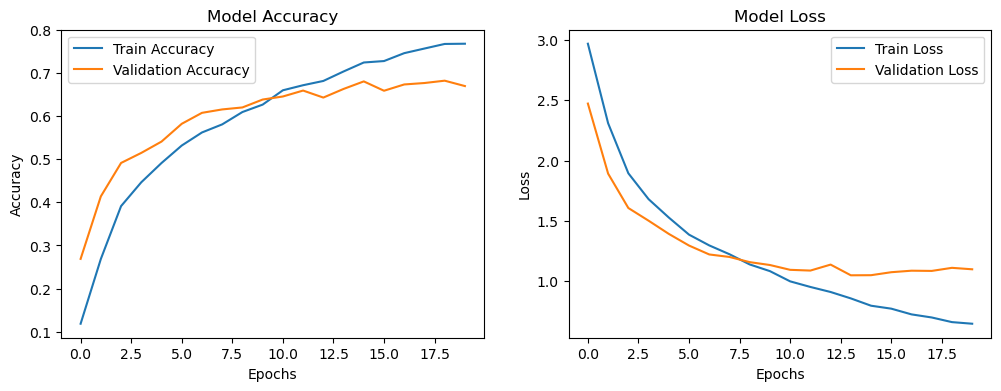

In [18]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

This is the exact same graph as done in the previous analysis, and I wanted to use this to build on this to see if it can be improved. So this the reason why I do not give an explanation about this. So this is the reason why I do not give an explanation about this.

In [24]:
def evaluate_model_per_class(model, X_test, y_test, label_map, images_per_class=50):
    # Reverse the label map to get class names
    reverse_label_map = {idx: label for label, idx in label_map.items()}

    # Exclude specific classes from evaluation
    excluded_classes = {"J", "Z", "Nothing", "Space"}
    valid_classes = {label: idx for label, idx in label_map.items() if label not in excluded_classes}
    
    overall_accuracy = []

    for label, idx in valid_classes.items():
        # Get indices of test samples belonging to the current class
        class_indices = np.where(y_test == idx)[0]
        
        # Select a fixed number of images for evaluation
        num_images = min(images_per_class, len(class_indices))
        if num_images == 0:
            print(f"Skipping class '{label}' as it has no samples in the test set.")
            continue

        # Selecting random images for evaluation form the fixed number
        selected_indices = np.random.choice(class_indices, size=num_images, replace=False)
        selected_images = X_test[selected_indices]
        true_labels = y_test[selected_indices]
        
        # Predict class probabilities and compute accuracy
        predictions = model.predict(selected_images, verbose=0)
        predicted_labels = np.argmax(predictions, axis=1)
        class_accuracy = np.mean(predicted_labels == true_labels)
        overall_accuracy.append(class_accuracy)
        
        # Display class accuracy
        print(f"Class '{label}' - Accuracy: {class_accuracy * 100:.2f}%")
        
        # Visualize up to 10 images
        plt.figure(figsize=(10, 5))
        for i in range(min(10, num_images)):
            plt.subplot(2, 5, i + 1)
            plt.imshow(selected_images[i].reshape(32, 32), cmap='gray')
            true_label = reverse_label_map[true_labels[i]]
            predicted_label = reverse_label_map[predicted_labels[i]]
            color = 'green' if true_label == predicted_label else 'red'
            plt.title(f"True: {true_label}\nPred: {predicted_label}", color=color)
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    # Compute and display overall accuracy
    mean_accuracy = np.mean(overall_accuracy)
    print(f"Overall accuracy across all valid classes: {mean_accuracy * 100:.2f}%")

Overall Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


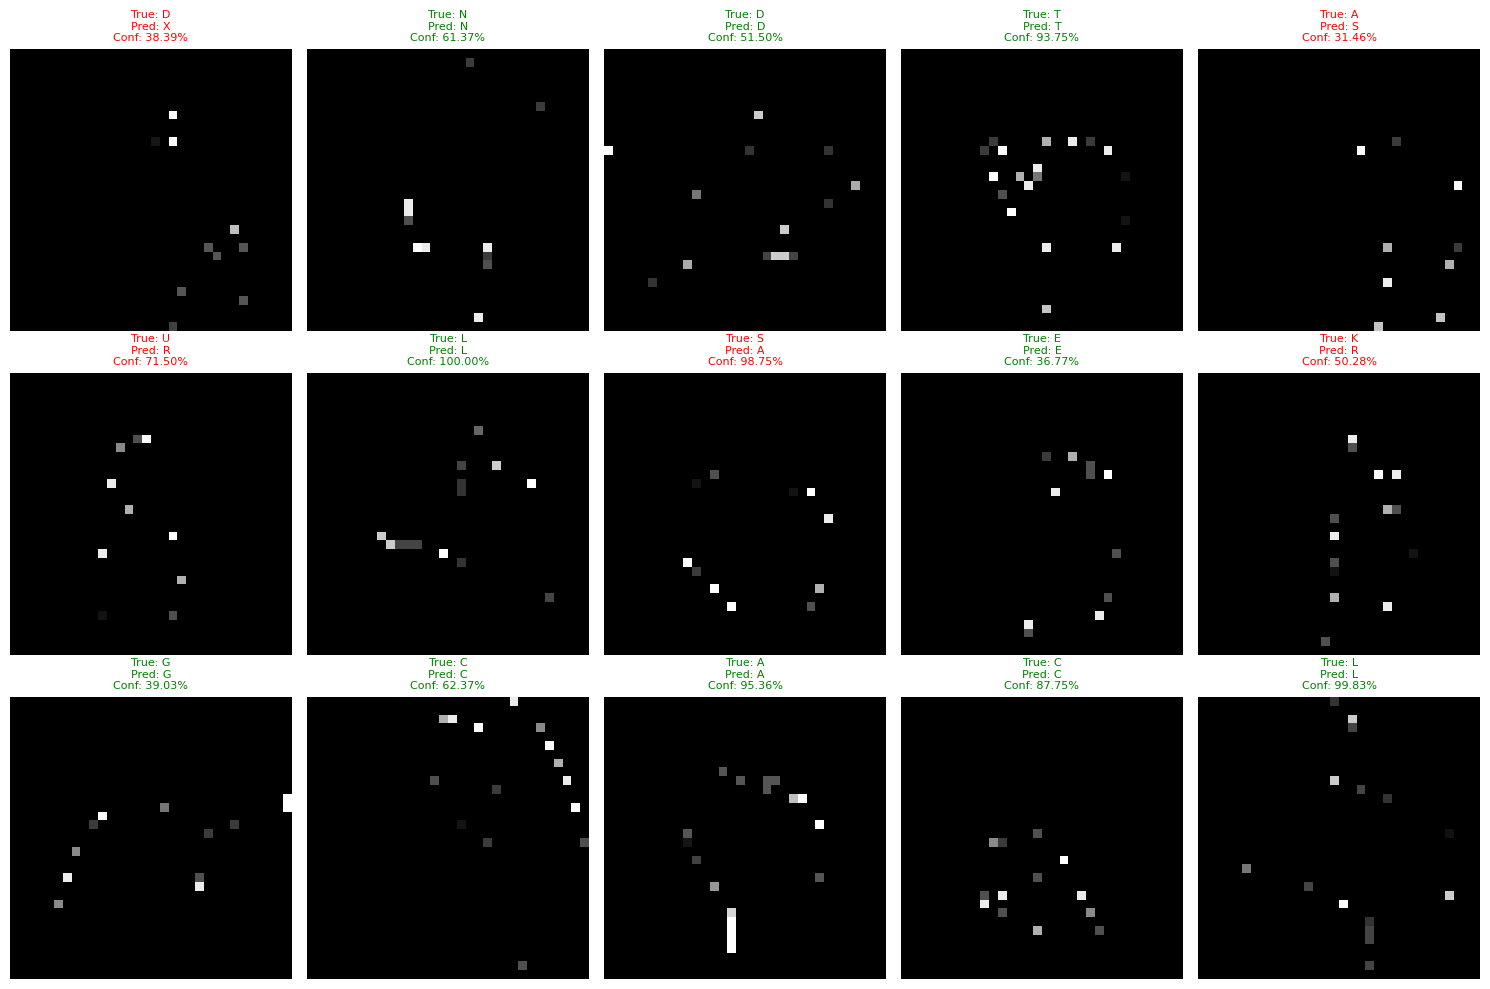

Per-Class Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━

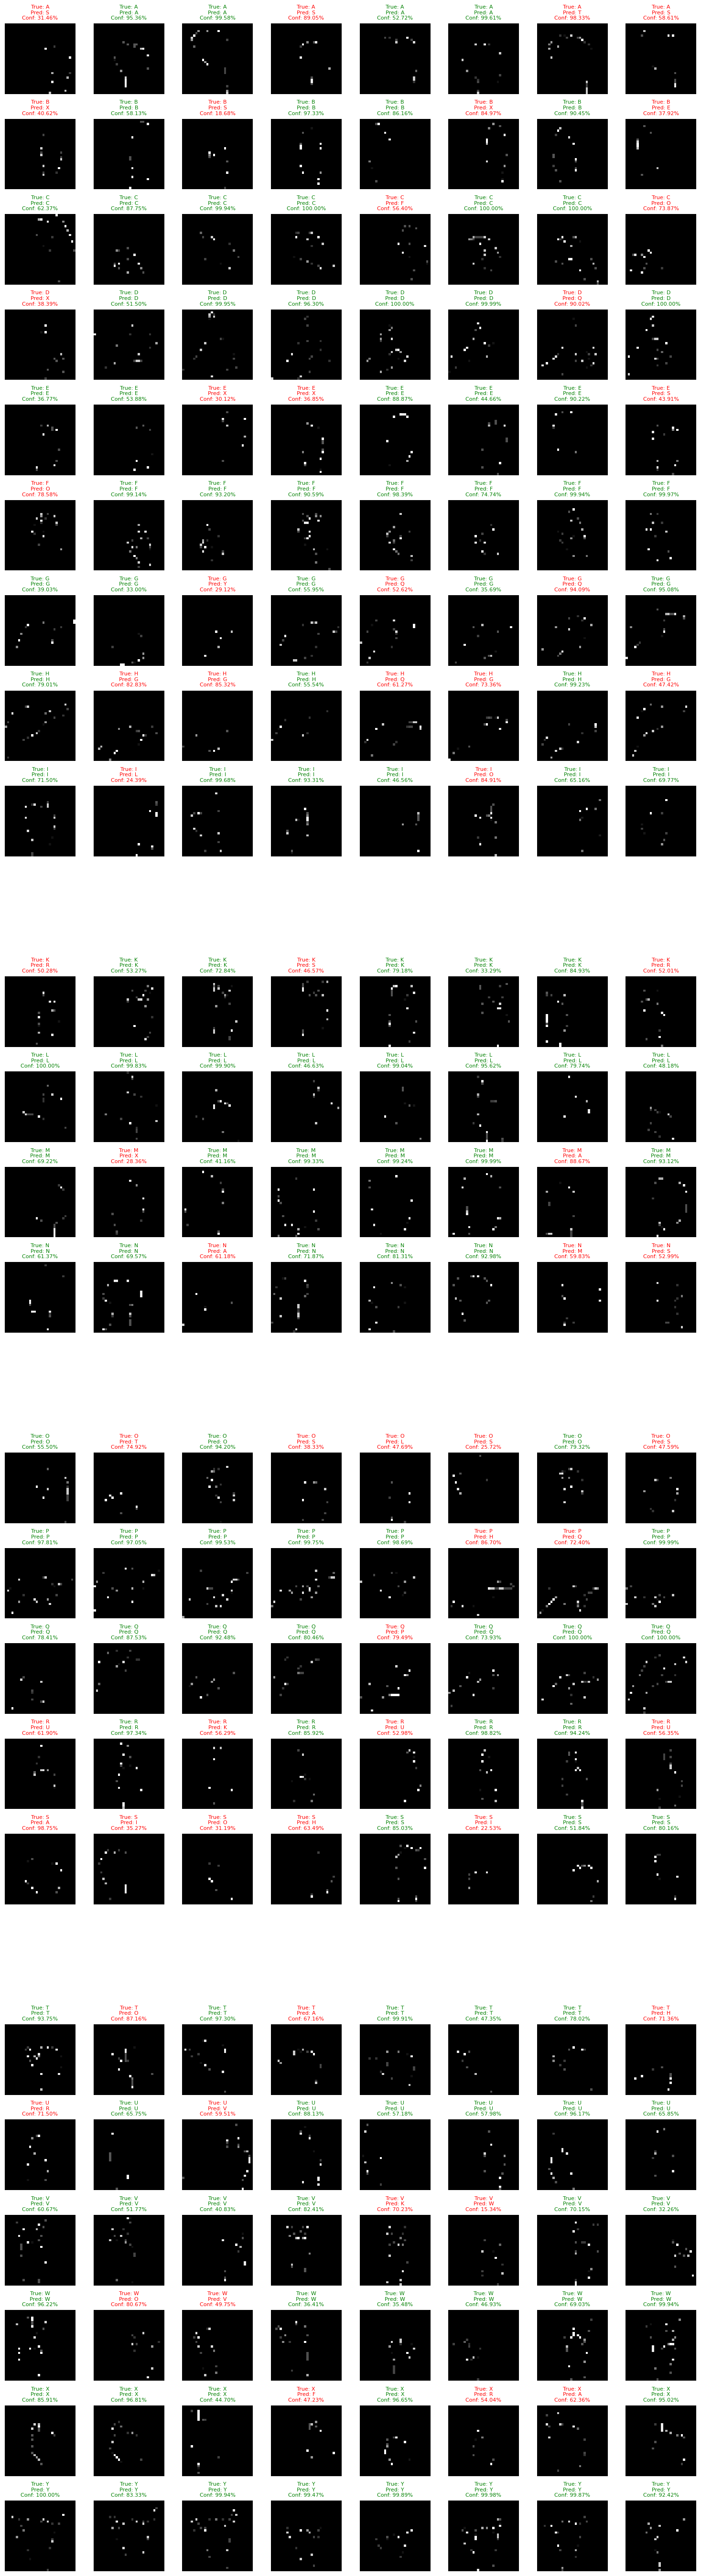

Class-Wise Accuracy Analysis:
Class 'A' - Accuracy: 50.00%


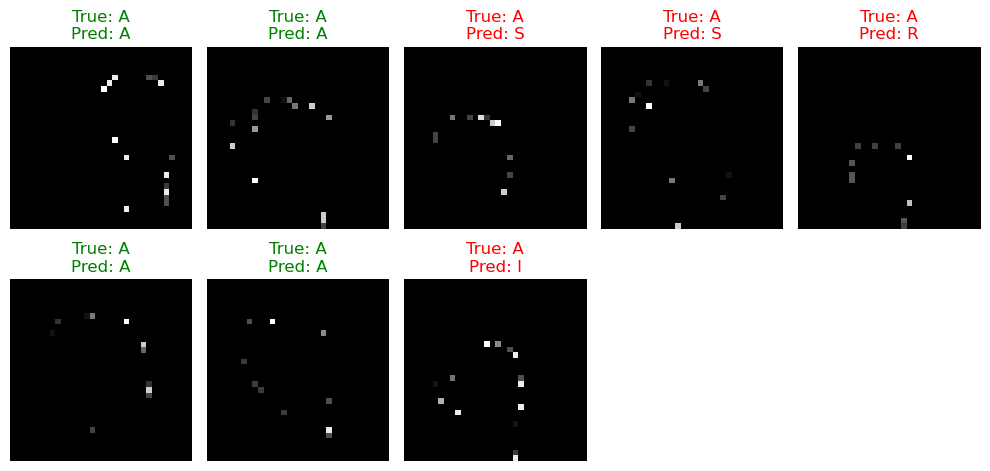

Class 'B' - Accuracy: 50.00%


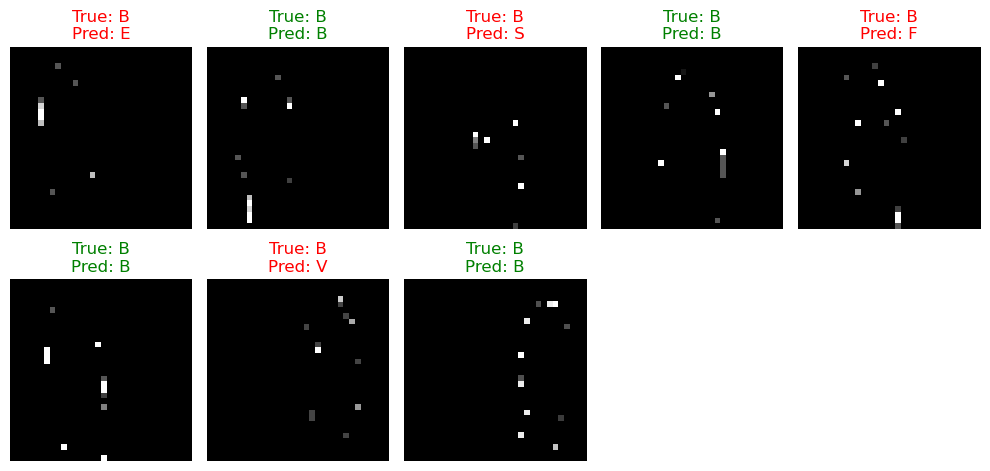

Class 'C' - Accuracy: 62.50%


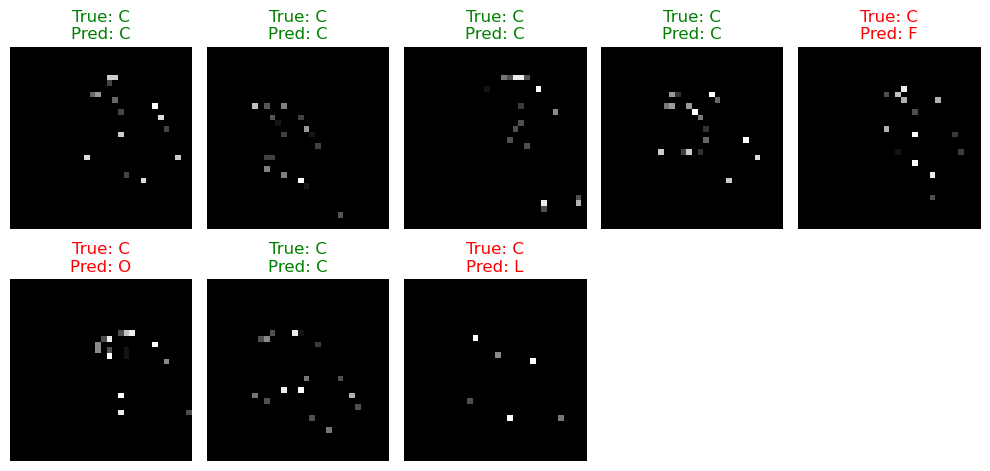

Class 'D' - Accuracy: 87.50%


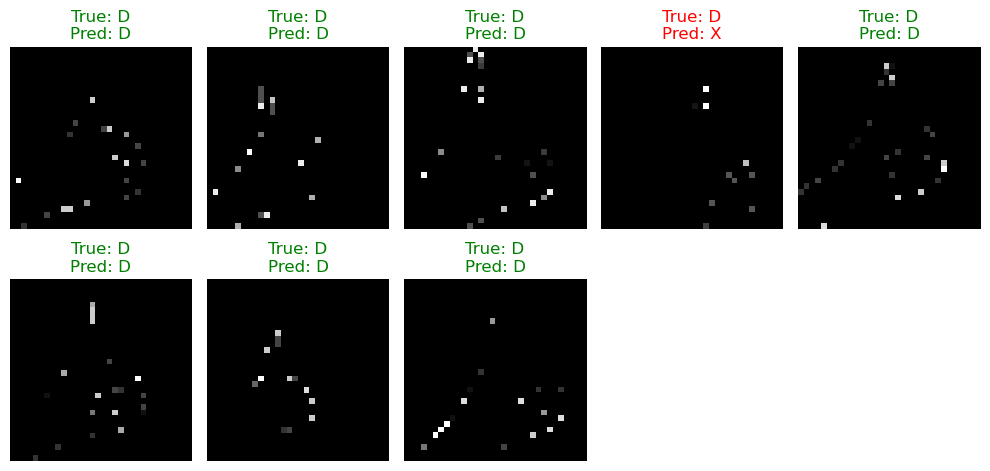

Class 'E' - Accuracy: 50.00%


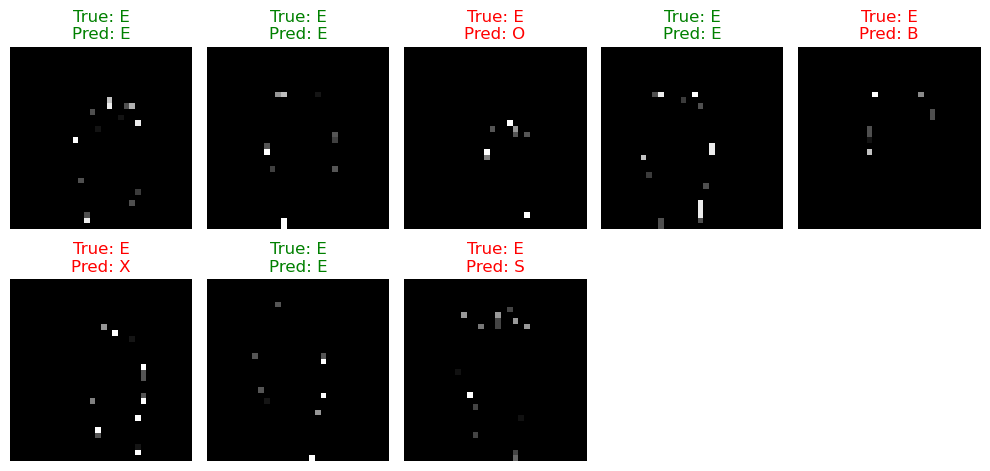

Class 'F' - Accuracy: 75.00%


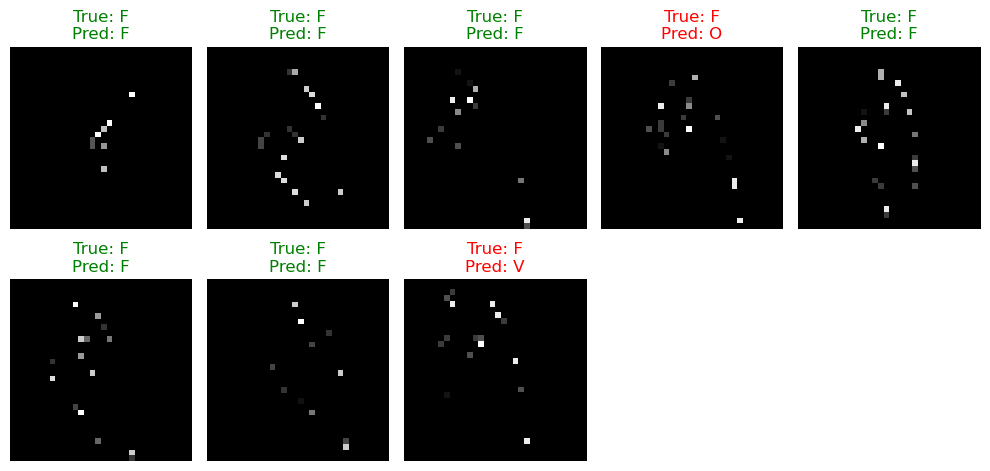

Class 'G' - Accuracy: 50.00%


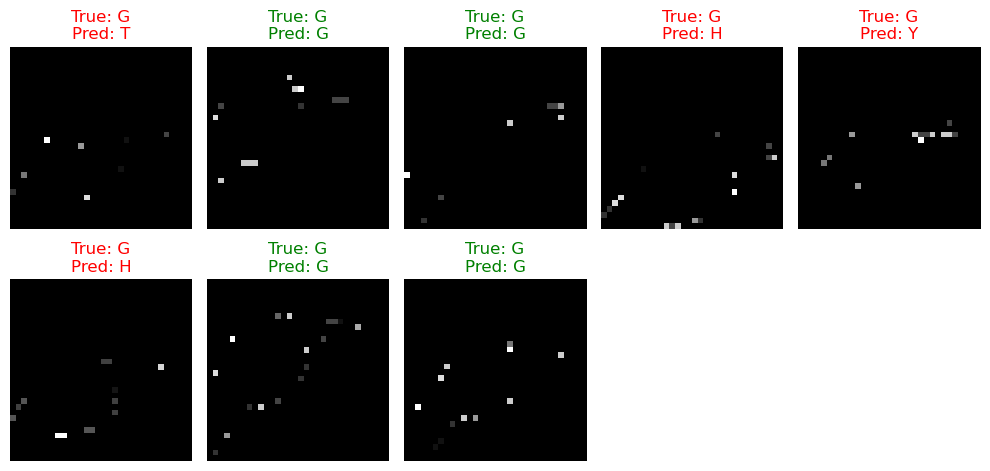

Class 'H' - Accuracy: 50.00%


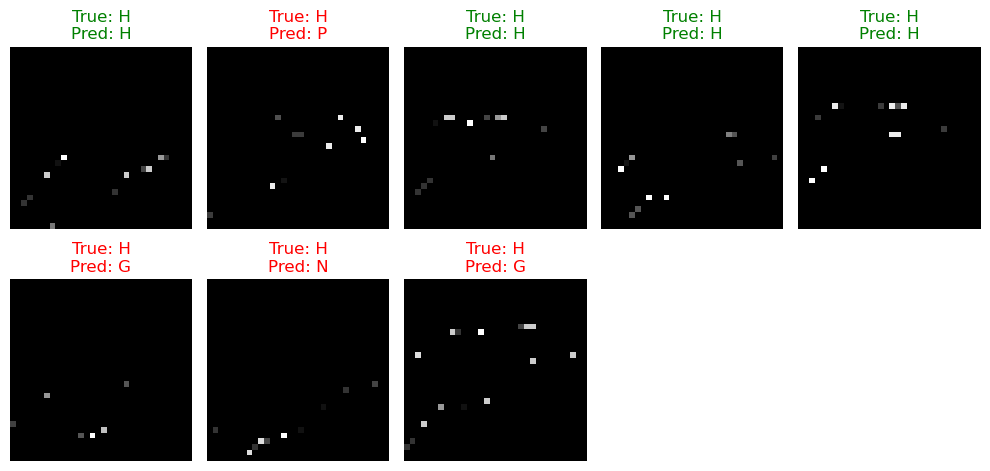

Class 'I' - Accuracy: 37.50%


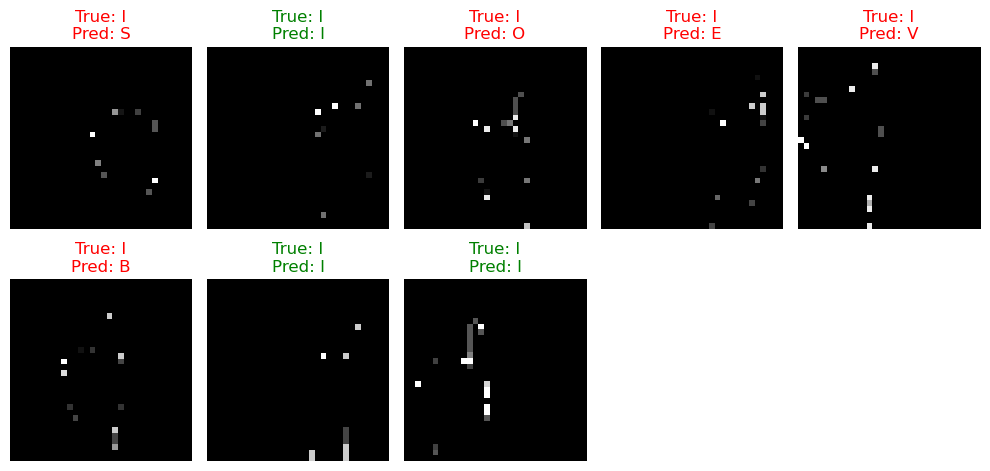

Class 'K' - Accuracy: 87.50%


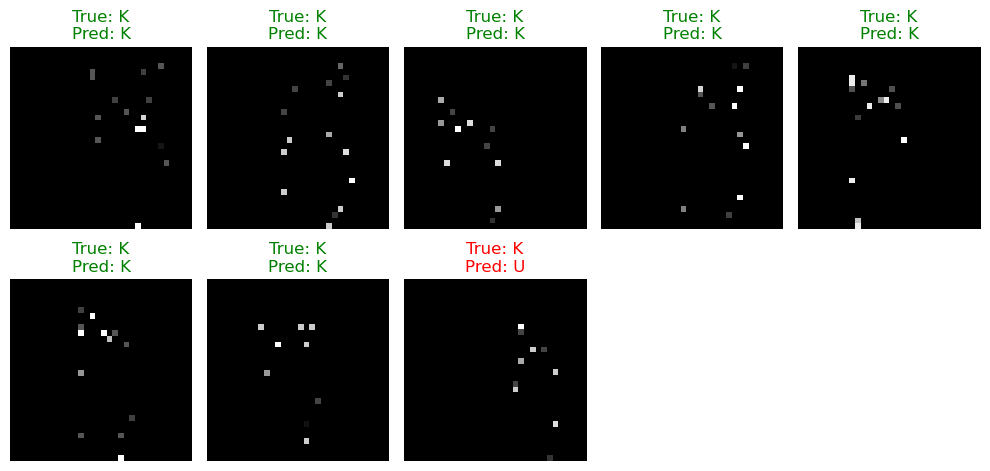

Class 'L' - Accuracy: 87.50%


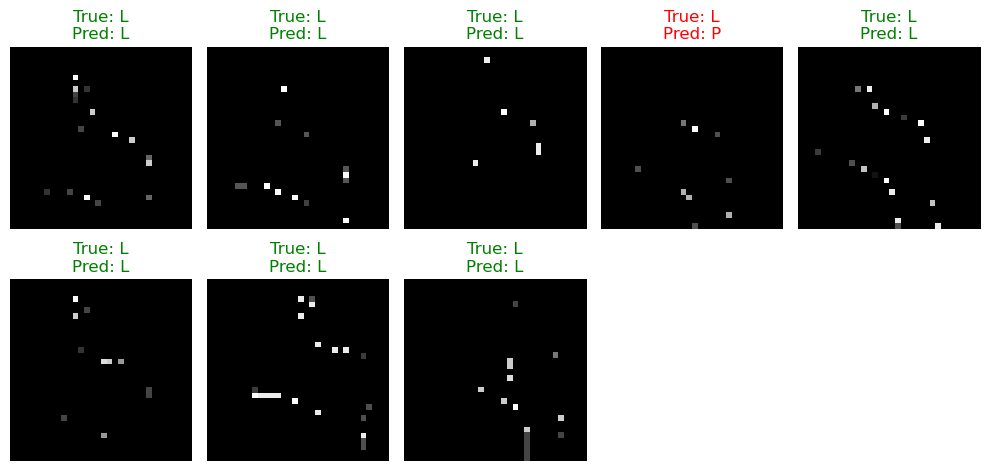

Class 'M' - Accuracy: 87.50%


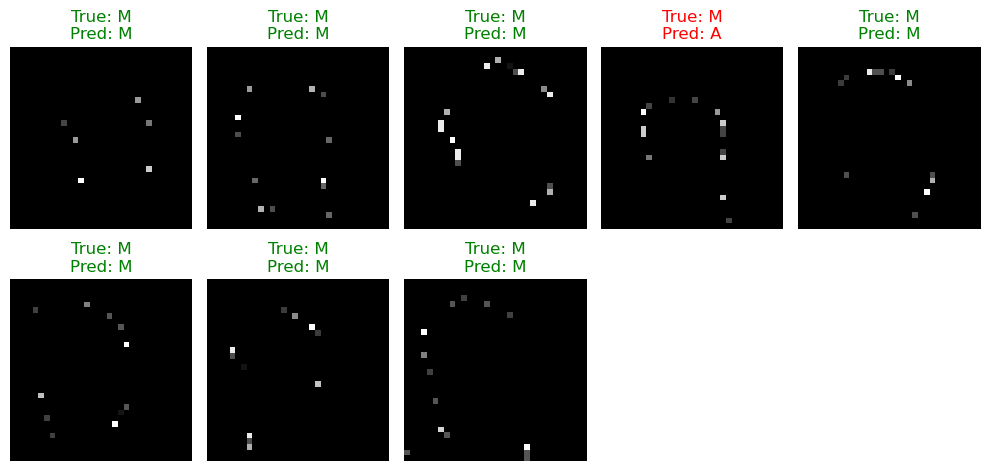

Class 'N' - Accuracy: 62.50%


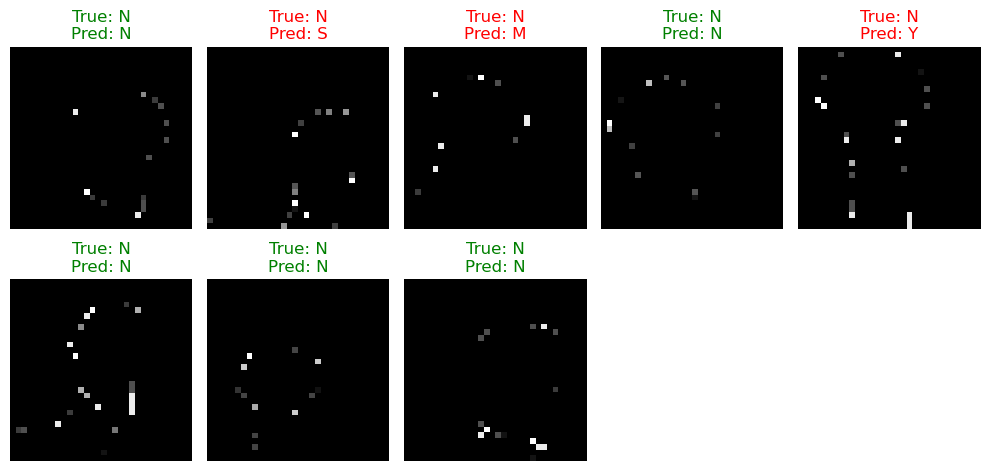

Class 'O' - Accuracy: 12.50%


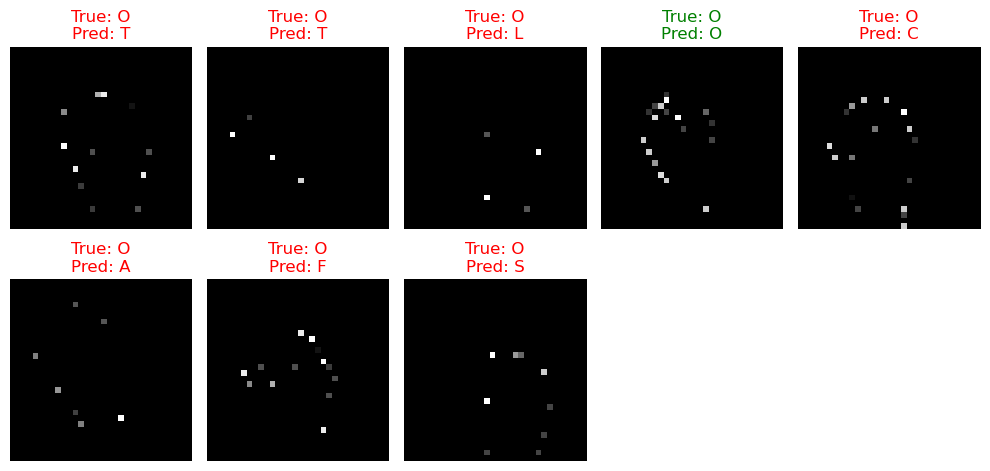

Class 'P' - Accuracy: 62.50%


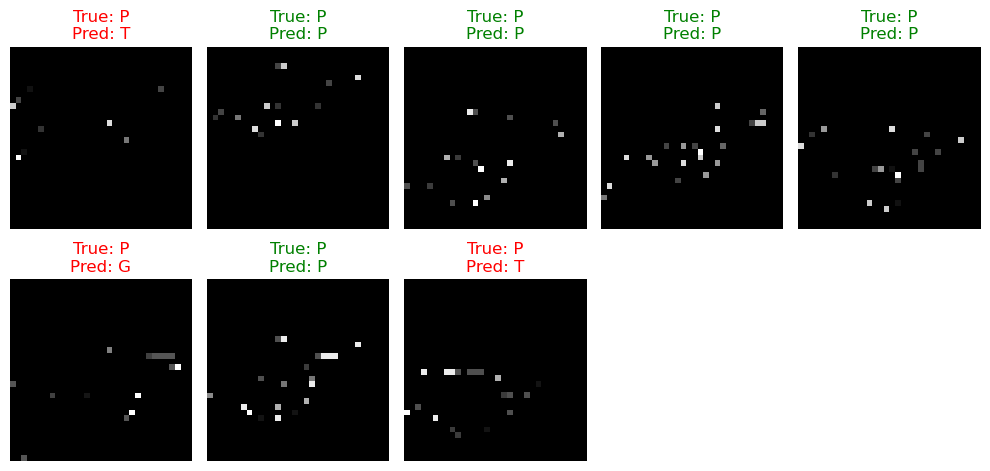

Class 'Q' - Accuracy: 75.00%


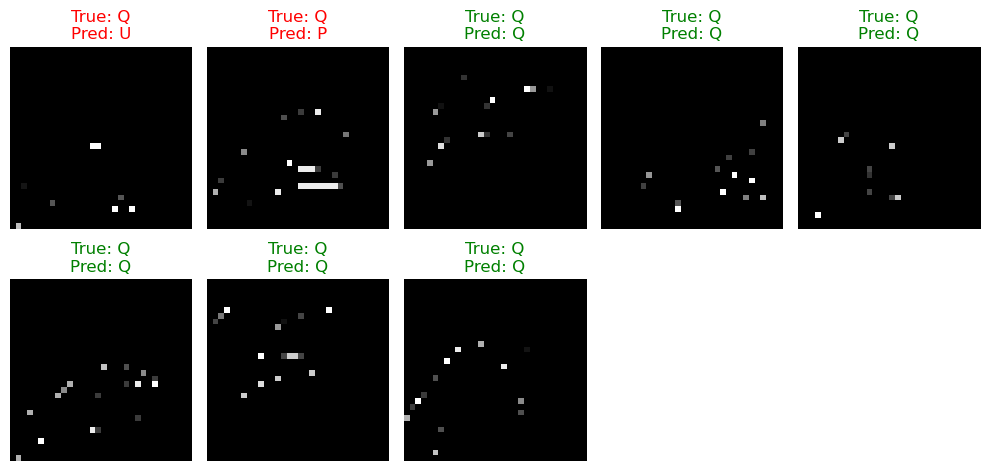

Class 'R' - Accuracy: 37.50%


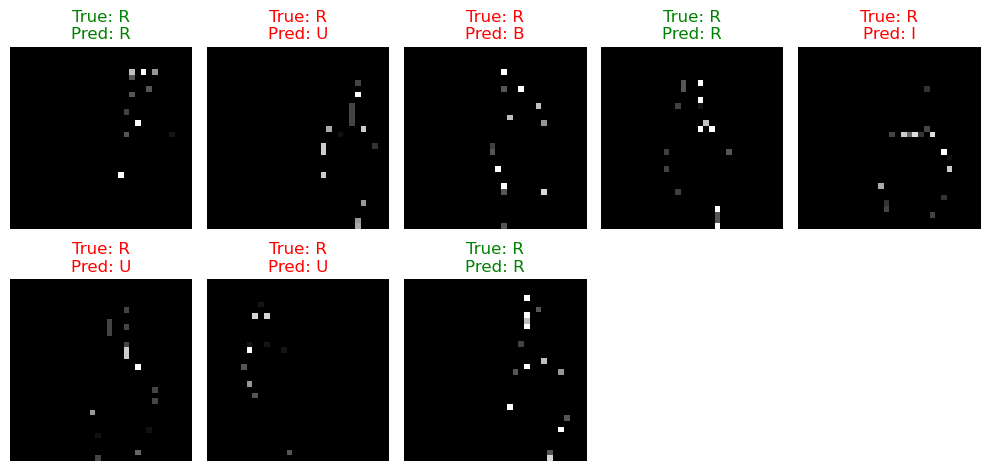

Class 'S' - Accuracy: 87.50%


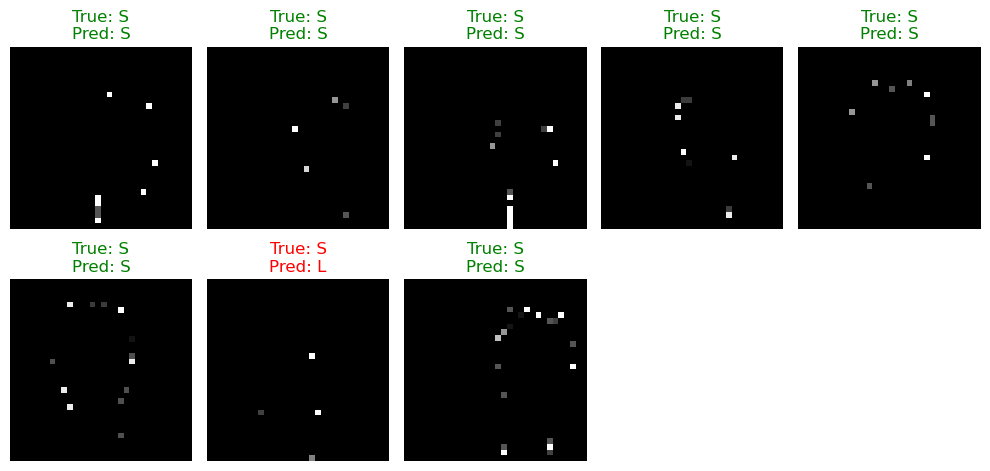

Class 'T' - Accuracy: 87.50%


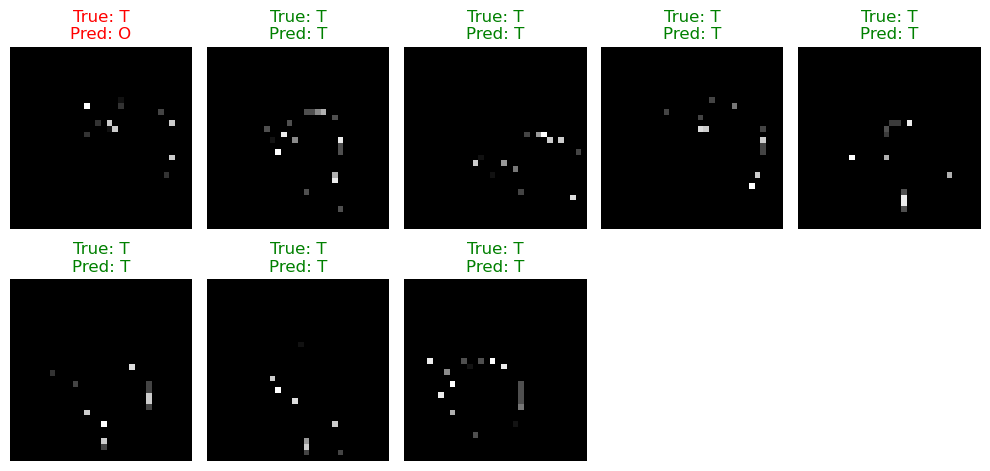

Class 'U' - Accuracy: 75.00%


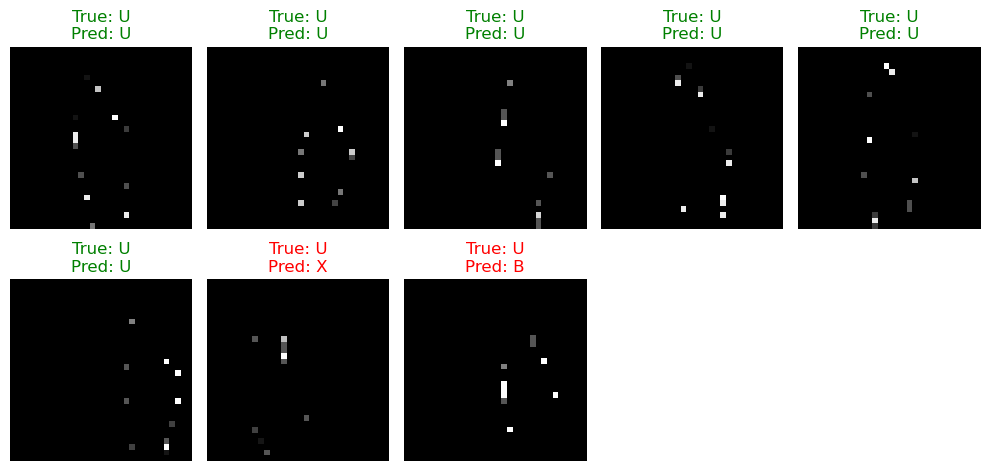

Class 'V' - Accuracy: 75.00%


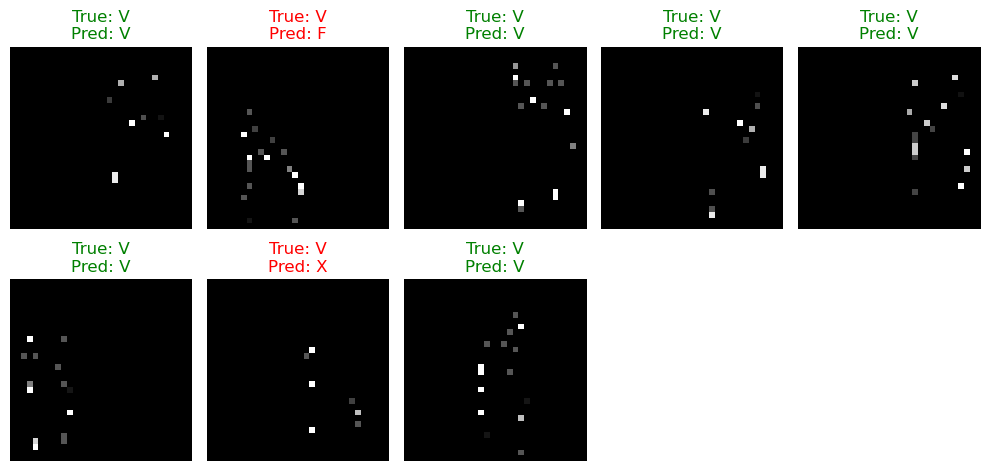

Class 'W' - Accuracy: 50.00%


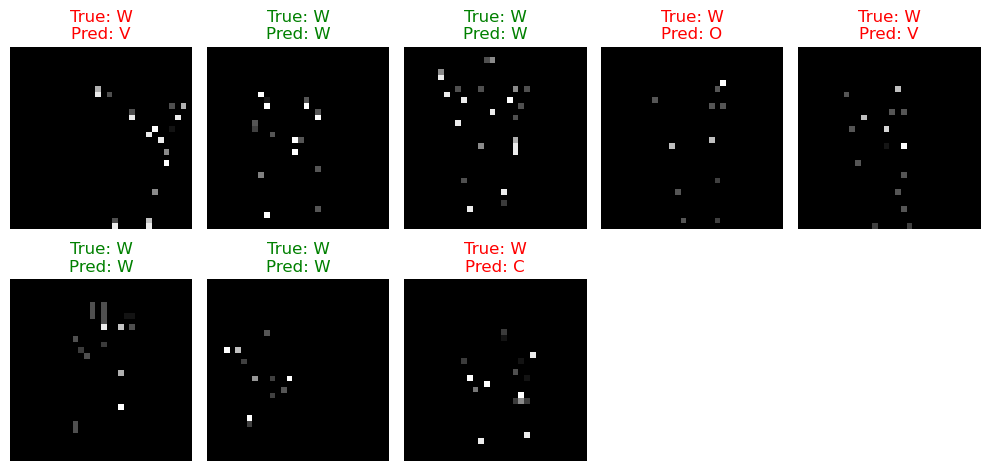

Class 'X' - Accuracy: 12.50%


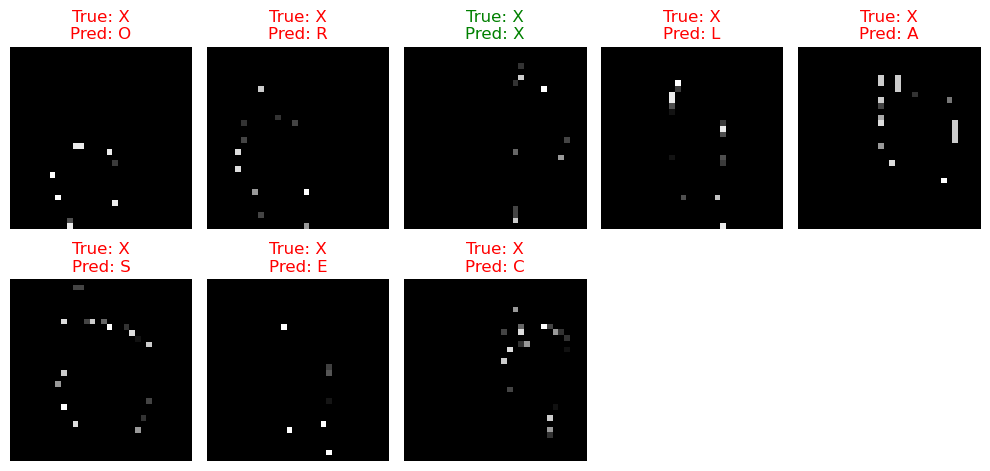

Class 'Y' - Accuracy: 87.50%


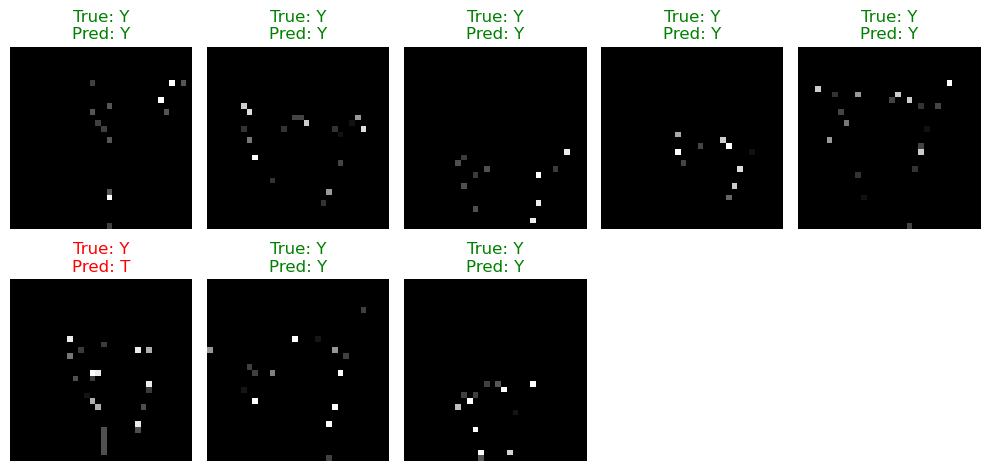

Overall accuracy across all valid classes: 62.50%


In [26]:
def analyze_model_predictions(model, X_test, y_test, label_map, img_size=(28, 28), num_predictions=15, num_per_class=8):
    
    # Convert labels if one-hot encoded
    if len(y_test.shape) > 1:
        y_test = np.argmax(y_test, axis=1)
    
    # Reverse label map for display
    reverse_label_map = {v: k for k, v in label_map.items()}
    
    # Overall predictions visualization
    print("Overall Prediction Analysis:")
    predictions = model.predict(X_test[:num_predictions])
    plt.figure(figsize=(15, 10))
    for i in range(num_predictions):
        plt.subplot(3, 5, i + 1)
        plt.imshow(X_test[i].reshape(img_size), cmap='gray')
        true_label = y_test[i]
        pred_label = np.argmax(predictions[i])
        is_correct = true_label == pred_label
        confidence = predictions[i][pred_label] * 100
        color = 'green' if is_correct else 'red'
        plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                  color=color, fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Per-class predictions visualization
    print("Per-Class Prediction Analysis:")
    class_samples = {cls: 0 for cls in range(len(label_map))}
    plt.figure(figsize=(15, len(label_map) * 2))
    for i, (img, true_label) in enumerate(zip(X_test, y_test)):
        if class_samples[true_label] < num_per_class:
            prediction = model.predict(img.reshape(1, *img_size, 1))
            pred_label = np.argmax(prediction)
            confidence = prediction[0][pred_label] * 100
            is_correct = true_label == pred_label
            color = 'green' if is_correct else 'red'
            
            plt.subplot(len(label_map), num_per_class, true_label * num_per_class + class_samples[true_label] + 1)
            plt.imshow(img.reshape(img_size), cmap='gray')
            plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                      color=color, fontsize=8)
            plt.axis('off')
            class_samples[true_label] += 1
        if all(count == num_per_class for count in class_samples.values()):
            break
    plt.tight_layout()
    plt.show()
    
    # Evaluate accuracy per class
    print("Class-Wise Accuracy Analysis:")
    evaluate_model_per_class(model, X_test, y_test, label_map, images_per_class=num_per_class)


analyze_model_predictions(model, 
                          X_test, 
                          y_test, 
                          label_map, 
                          img_size=(32, 32), 
                          num_predictions=15, 
                          num_per_class=8)

If I look at the result of my evaluation model, it still has a low accuracy, and you can see that it has a lot more difficulties predicting the classes as in my previous analysis. I still think I can increase the accuracy by adding more epochs, giving my model some more time to train and see what the results are. If this is still not to my satisfaction, then we are going to tweak some argumentation in hope of getting better results.

In [28]:
# Define variables to are going to be used for the create dataset method
dataset_path = 'ASL_Dataset/Train'
exclude_folders = ["J", "Z", "Nothing", "Space"]
num_images = 500  

# Use the method with the created variables
X, y, label_map = create_dataset(dataset_path, img_size=(32, 32), num_images=num_images, exclude_folders=exclude_folders)

# Verify the shapes of X and y
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the CNN model
input_shape = (32, 32, 1)  # Image shape with channel
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(
    X_train, 
    y_train, 
    epochs=30, 
    validation_data=(X_test, y_test), 
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping folder: J
Skipping folder: Nothing
Skipping folder: Space
Skipping folder: Z
Shape of X: (12000, 32, 32, 1)
Shape of y: (12000,)
Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.0840 - loss: 3.1478 - val_accuracy: 0.2929 - val_loss: 2.3447
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2671 - loss: 2.3389 - val_accuracy: 0.4746 - val_loss: 1.7472
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3970 - loss: 1.8494 - val_accuracy: 0.5088 - val_loss: 1.5663
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4633 - loss: 1.6121 - val_accuracy: 0.5429 - val_loss: 1.3882
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5204 - loss: 1.4372 - val_accuracy: 0.5767 - val_loss: 1.2952
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5700 - loss: 1.2867 - val_accuracy: 0.5900 - val_loss: 1.2486
Epoch 7/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5947 - loss: 1.1915 - va

I'm currently experimenting with the number of epochs to see how it affects my dataset and whether it can, in fact, improve my accuracy as I hope. I've included this to demonstrate my methodology, my thought process, and the steps I take to refine my model.

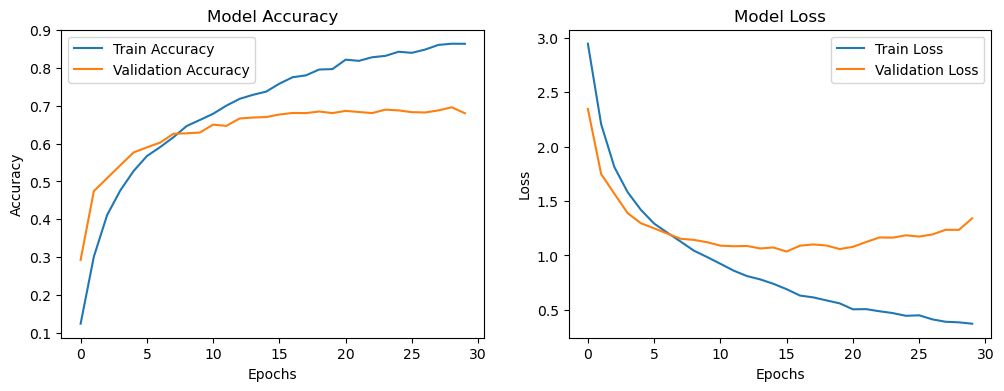

In [30]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

The graph illustrates the model's performance during training and validation, with accuracy increasing steadily and converging as epochs progress, while loss decreases consistently, indicating the model's learning process and improvement in predicting the correct outputs.

If I look at these graph it does seem to me that it is not a healthy graph because the model is performing significantly better on the training data than on the unseen validation data. This could happen because the model is memorizing the training data rather than learning generalized patterns. So this should indicate there is still a overfitting issue. I want to see if I can tweak this. 

Maybe because I added to much layers in my CNN so let's trim it down to two and see what happends whit the training of the dataset. i'm also going to increase the amount of data that is used from 500 to 1000 for training and playing around with some of the argumentation traits. Making soem adjustments to the trashold 1 and teh grassian blur that is added to my images.

In [29]:
def preprocess_image_for_cnn2(img, img_size=(32, 32)):
    # Apply Gaussian blur to reduce noise
    img = cv2.GaussianBlur(img, (3, 3), 0)
    
    # Apply Canny Edge Detection to get the outline
    edges = cv2.Canny(img, threshold1=70, threshold2=150)
    
    # Resize to the desired input size
    edges = cv2.resize(edges, img_size)
    
    # Normalize pixel values
    edges = edges / 255.0
    
    return edges  

In [17]:
def build_cnn_model2(input_shape, num_classes):
    model = Sequential([
        # Convolutional layers
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        # Flatten the feature map
        Flatten(),

        # Fully connected layers
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [19]:
def create_dataset2(dataset_path, img_size=(64, 64), num_images=None, exclude_folders=None):
    # Ensures that it defaults to an empty list if None
    if exclude_folders is None:
        exclude_folders = [] 
    
    X = []
    y = []
    labels = sorted(os.listdir(dataset_path)) 
    label_map = {label: idx for idx, label in enumerate(labels)}  # Create a label map

    for label in labels:
        if label in exclude_folders:
            print(f"Skipping folder: {label}")
            continue
        
        label_path = os.path.join(dataset_path, label)
        if os.path.isdir(label_path):
            # Get the list of image files and limit to num_images
            image_files = [file for file in os.listdir(label_path) if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))]
            if num_images is not None:
                image_files = image_files[:num_images]  # Limit the number of images per folder

            # Iterate through the filtered image files
            for file in image_files:
                file_path = os.path.join(label_path, file)
                try:
                    # Read the image
                    img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
                    
                    # Check if the image was loaded correctly
                    if img is None:
                        print(f"Error loading image: {file_path}")
                        continue
                    
                    # Apply preprocessing
                    preprocessed_img = preprocess_image_for_cnn2(img, img_size)
                    
                    # Append the preprocessed image and its corresponding label
                    X.append(preprocessed_img)
                    y.append(label_map[label])

                except ValueError as e:
                    print(f"Error processing {file}: {e}")
                    continue

    # Convert lists to numpy arrays
    X = np.array(X).reshape(-1, img_size[0], img_size[1], 1)  # Add channel dimension
    y = np.array(y)
    
    # Ensure that X and y have the same length
    assert len(X) == len(y), "The number of images and labels don't match"
    
    return X, y, label_map

In [35]:
# Define variables to are going to be used for the create dataset method
dataset_path = 'ASL_Dataset/Train'
exclude_folders = ["J", "Z", "Nothing", "Space"]
num_images = 1000  

# Use the method with the created variables
X, y, label_map = create_dataset2(dataset_path, img_size=(32, 32), num_images=num_images, exclude_folders=exclude_folders)

# Verify the shapes of X and y
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the CNN model
input_shape = (32, 32, 1)  # Image shape with channel
num_classes = len(label_map)
model = build_cnn_model2(input_shape, num_classes)

# Train the model
history = model.fit(
    X_train, 
    y_train, 
    epochs=70, 
    validation_data=(X_test, y_test), 
    batch_size=32
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping folder: J
Skipping folder: Nothing
Skipping folder: Space
Skipping folder: Z
Shape of X: (24000, 32, 32, 1)
Shape of y: (24000,)
Epoch 1/70
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.1441 - loss: 2.9008 - val_accuracy: 0.4031 - val_loss: 2.0000
Epoch 2/70
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3459 - loss: 2.0877 - val_accuracy: 0.5337 - val_loss: 1.5267
Epoch 3/70
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4434 - loss: 1.7301 - val_accuracy: 0.5867 - val_loss: 1.3245
Epoch 4/70
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4924 - loss: 1.5587 - val_accuracy: 0.6196 - val_loss: 1.2176
Epoch 5/70
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5362 - loss: 1.4024 - val_accuracy: 0.6329 - val_loss: 1.1844
Epoch 6/70
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5645 - loss: 1.3175 - val_accuracy: 0.6706 - val_loss: 1.0481
Epoch 7/70
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6049 - loss: 1.1935 - val_ac

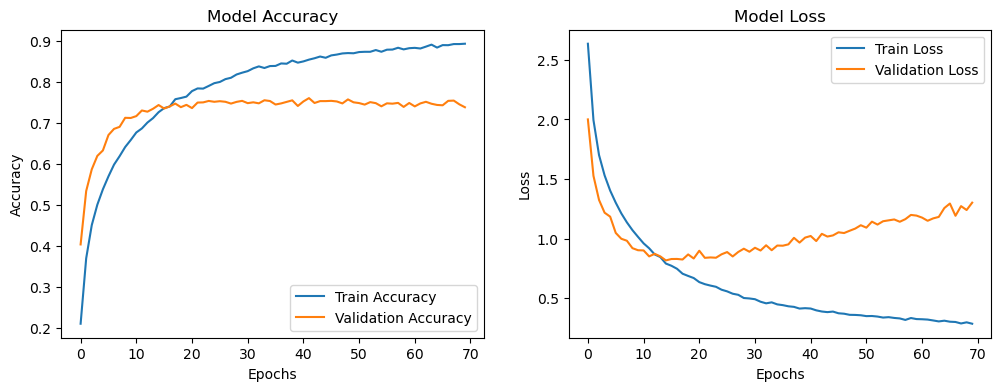

In [37]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

Since I could see from the epoch amount that it had stopped increasing, indicating that the model had been trained to its maximum potential, I used the early stopping concept here. Early stopping is when you stop before the number of epochs you have left, usually when you are satisfied with the outcome.

The next step is to evaluate the model to see how well it performs.

In [39]:
def evaluate_model_per_class2(model, X_test, y_test, label_map, images_per_class=50):
    # Reverse the label map to get class names
    reverse_label_map = {idx: label for label, idx in label_map.items()}

    # Exclude specific classes from evaluation
    excluded_classes = {"J", "Z", "Nothing", "Space"}
    valid_classes = {label: idx for label, idx in label_map.items() if label not in excluded_classes}
    
    overall_accuracy = []

    for label, idx in valid_classes.items():
        # Get indices of test samples belonging to the current class
        class_indices = np.where(y_test == idx)[0]
        
        # Select a fixed number of images for evaluation
        num_images = min(images_per_class, len(class_indices))
        if num_images == 0:
            print(f"Skipping class '{label}' as it has no samples in the test set.")
            continue

        # Selecting random images for evaluation form the fixed number
        selected_indices = np.random.choice(class_indices, size=num_images, replace=False)
        selected_images = X_test[selected_indices]
        true_labels = y_test[selected_indices]
        
        # Predict class probabilities and compute accuracy
        predictions = model.predict(selected_images, verbose=0)
        predicted_labels = np.argmax(predictions, axis=1)
        class_accuracy = np.mean(predicted_labels == true_labels)
        overall_accuracy.append(class_accuracy)
        
        # Display class accuracy
        print(f"Class '{label}' - Accuracy: {class_accuracy * 100:.2f}%")
        
        # Visualize up to 10 images
        plt.figure(figsize=(10, 5))
        for i in range(min(10, num_images)):
            plt.subplot(2, 5, i + 1)
            plt.imshow(selected_images[i].reshape(32, 32), cmap='gray')
            true_label = reverse_label_map[true_labels[i]]
            predicted_label = reverse_label_map[predicted_labels[i]]
            color = 'green' if true_label == predicted_label else 'red'
            plt.title(f"True: {true_label}\nPred: {predicted_label}", color=color)
            plt.axis('off')
        plt.tight_layout()
        plt.show()

    # Compute and display overall accuracy
    mean_accuracy = np.mean(overall_accuracy)
    print(f"Overall accuracy across all valid classes: {mean_accuracy * 100:.2f}%")

In [41]:
def analyze_model_predictions2(model, X_test, y_test, label_map, img_size=(28, 28), num_predictions=15, num_per_class=8):
    
    # Convert labels if one-hot encoded
    if len(y_test.shape) > 1:
        y_test = np.argmax(y_test, axis=1)
    
    # Reverse label map for display
    reverse_label_map = {v: k for k, v in label_map.items()}
    
    # Overall predictions visualization
    print("Overall Prediction Analysis:")
    predictions = model.predict(X_test[:num_predictions])
    plt.figure(figsize=(15, 10))
    for i in range(num_predictions):
        plt.subplot(3, 5, i + 1)
        plt.imshow(X_test[i].reshape(img_size), cmap='gray')
        true_label = y_test[i]
        pred_label = np.argmax(predictions[i])
        is_correct = true_label == pred_label
        confidence = predictions[i][pred_label] * 100
        color = 'green' if is_correct else 'red'
        plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                  color=color, fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Per-class predictions visualization
    print("Per-Class Prediction Analysis:")
    class_samples = {cls: 0 for cls in range(len(label_map))}
    plt.figure(figsize=(15, len(label_map) * 2))
    for i, (img, true_label) in enumerate(zip(X_test, y_test)):
        if class_samples[true_label] < num_per_class:
            prediction = model.predict(img.reshape(1, *img_size, 1))
            pred_label = np.argmax(prediction)
            confidence = prediction[0][pred_label] * 100
            is_correct = true_label == pred_label
            color = 'green' if is_correct else 'red'
            
            plt.subplot(len(label_map), num_per_class, true_label * num_per_class + class_samples[true_label] + 1)
            plt.imshow(img.reshape(img_size), cmap='gray')
            plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                      color=color, fontsize=8)
            plt.axis('off')
            class_samples[true_label] += 1
        if all(count == num_per_class for count in class_samples.values()):
            break
    plt.tight_layout()
    plt.show()
    
    # Evaluate accuracy per class
    print("Class-Wise Accuracy Analysis:")
    evaluate_model_per_class2(model, X_test, y_test, label_map, images_per_class=num_per_class)

Overall Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


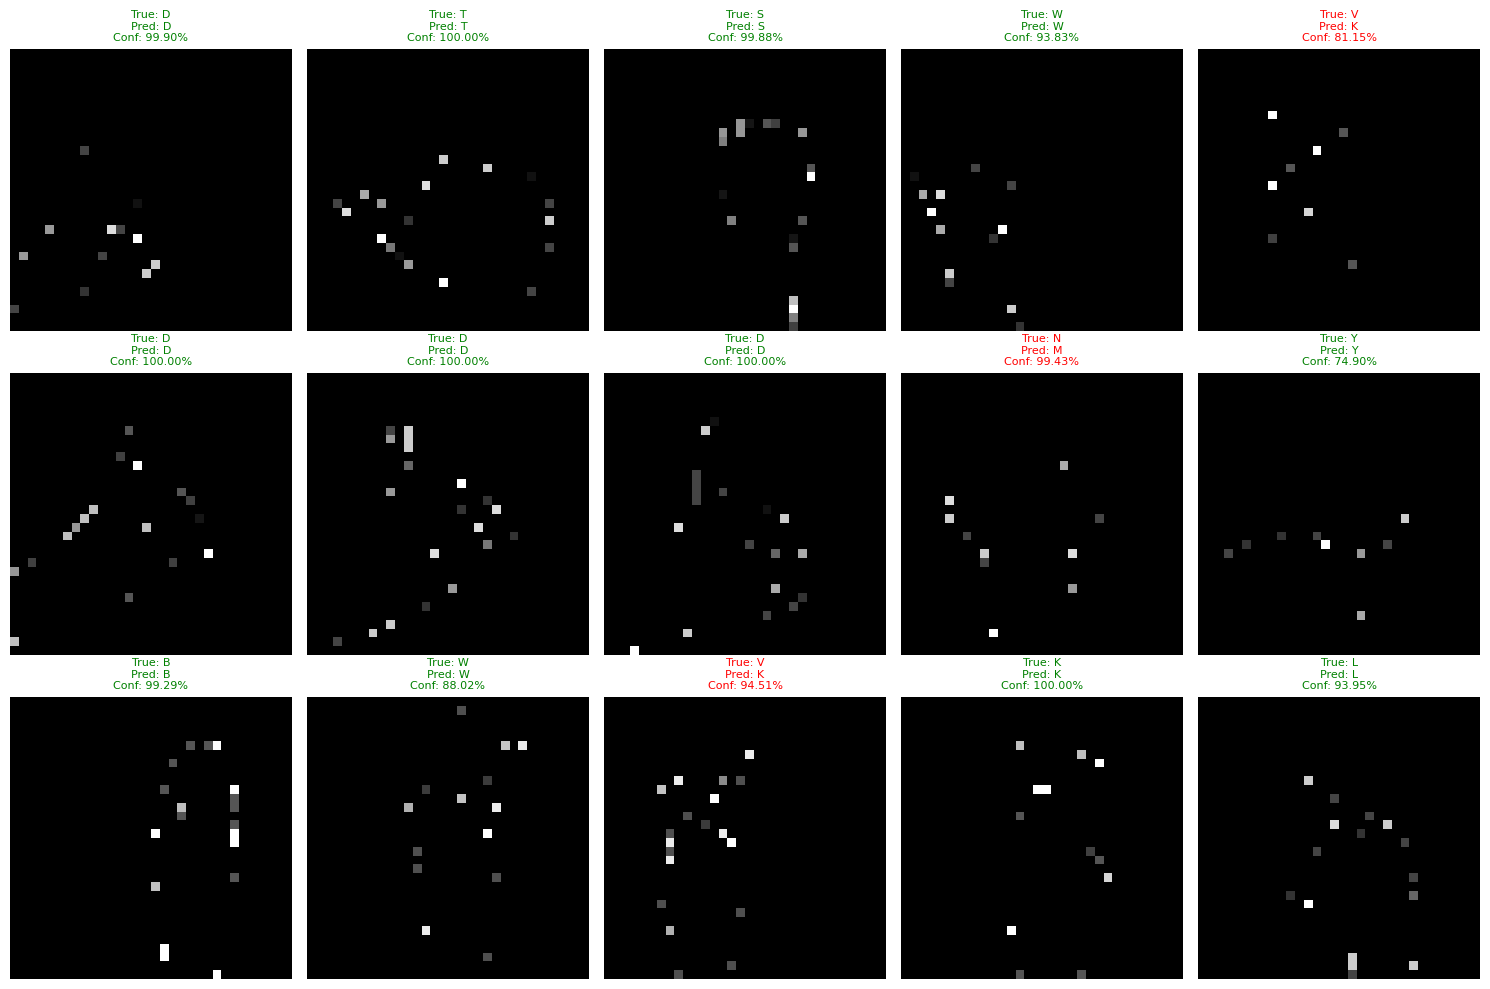

Per-Class Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━

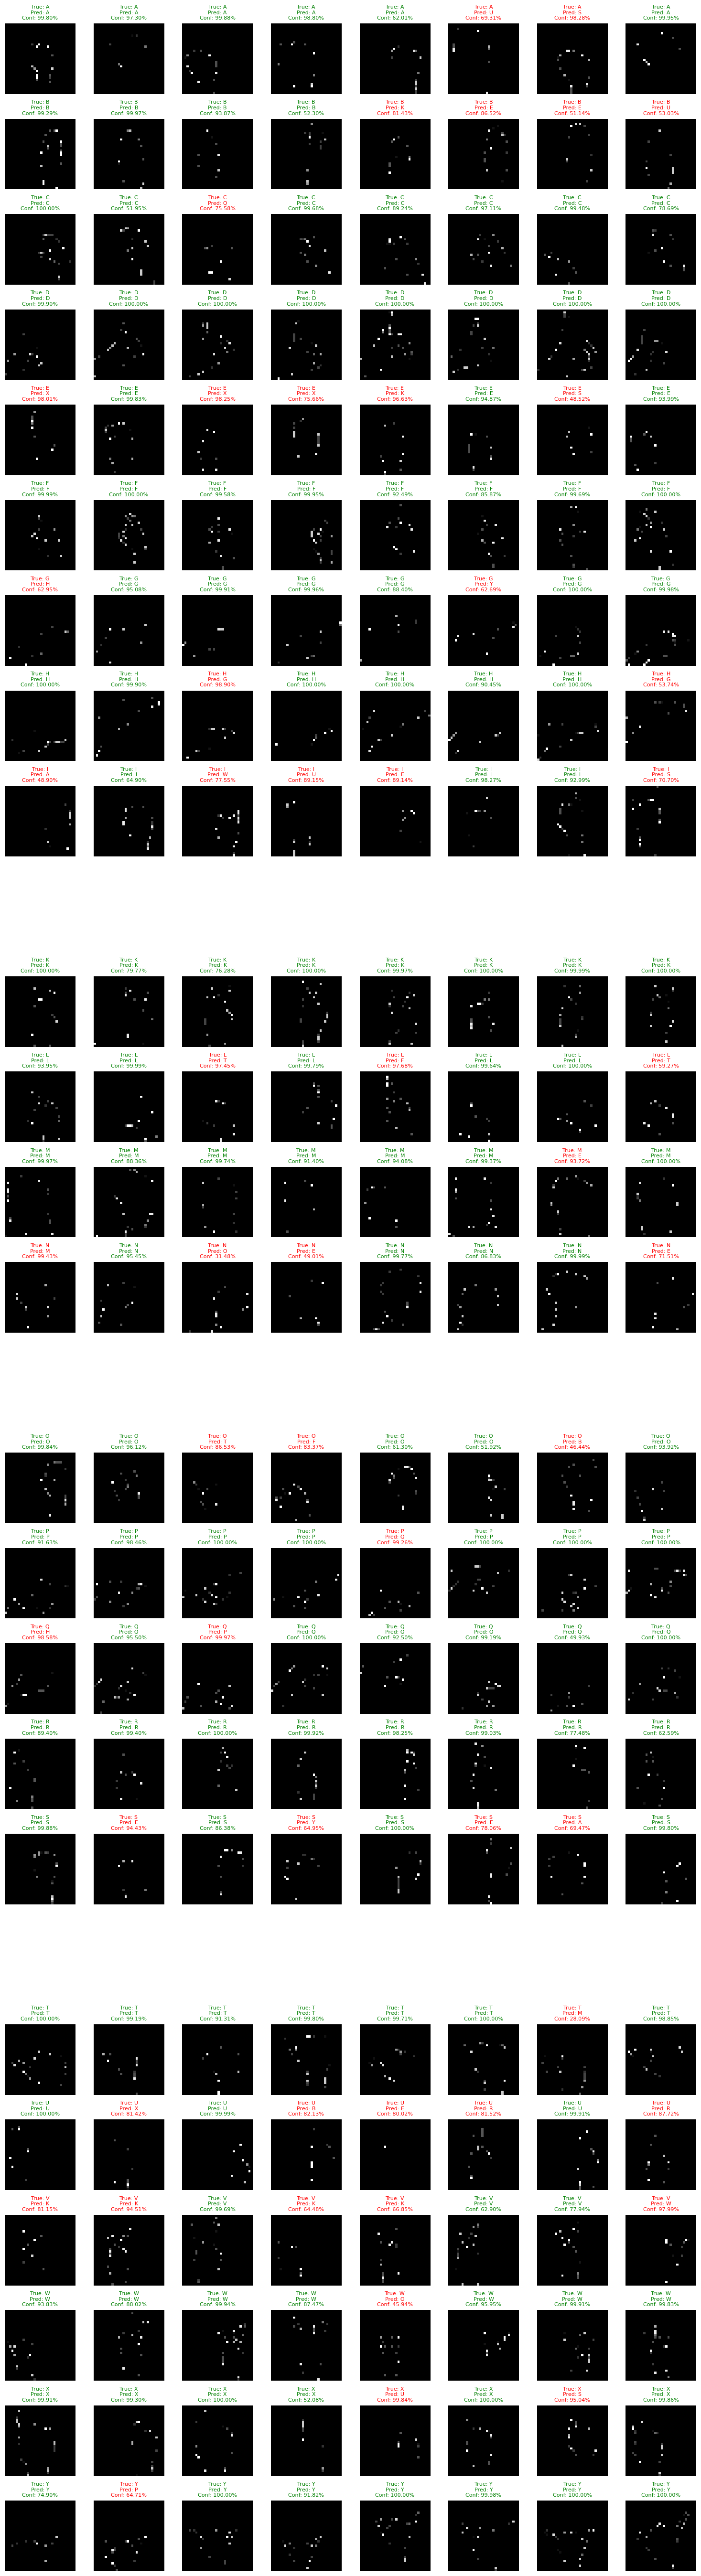

Class-Wise Accuracy Analysis:
Class 'A' - Accuracy: 37.50%


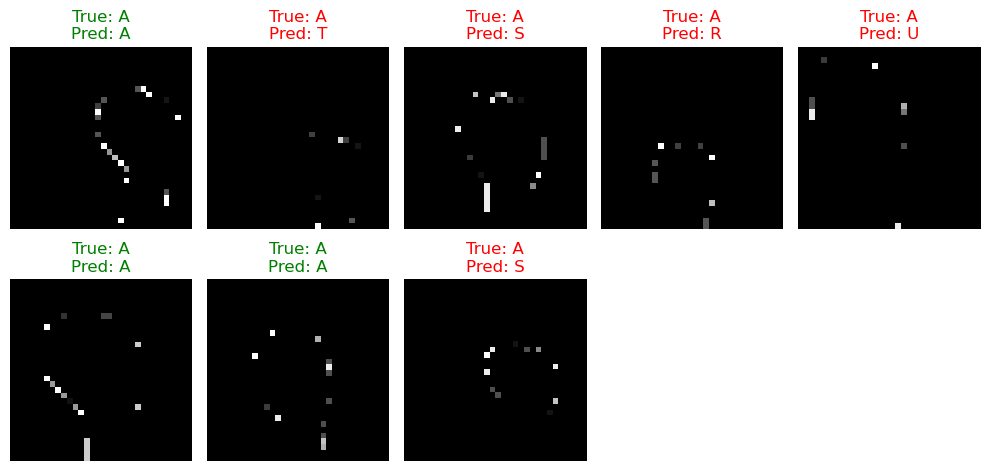

Class 'B' - Accuracy: 50.00%


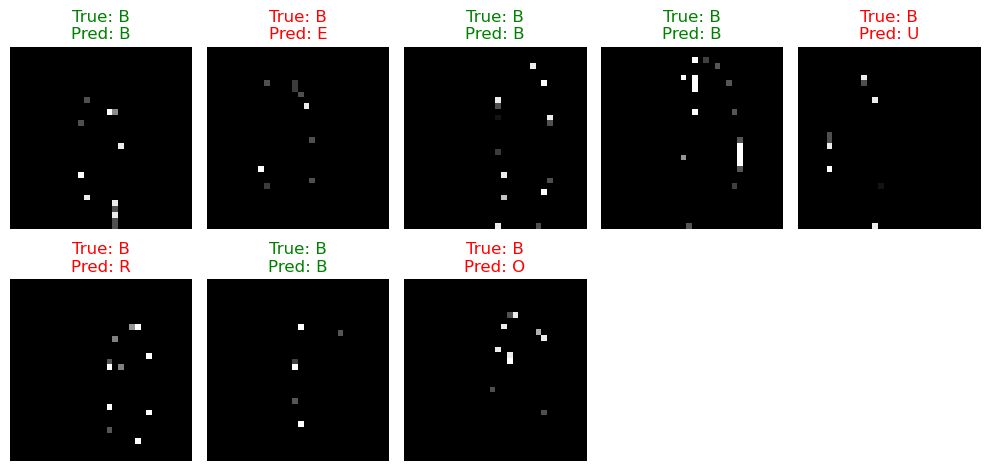

Class 'C' - Accuracy: 87.50%


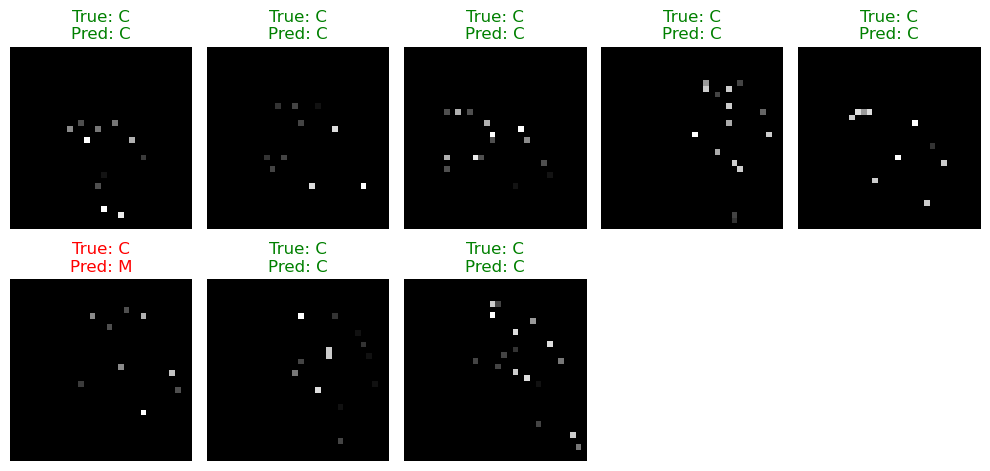

Class 'D' - Accuracy: 100.00%


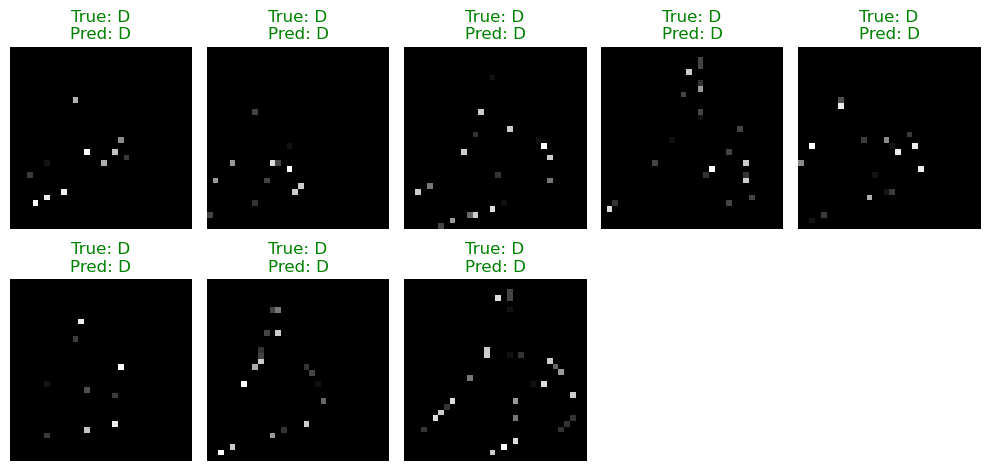

Class 'E' - Accuracy: 25.00%


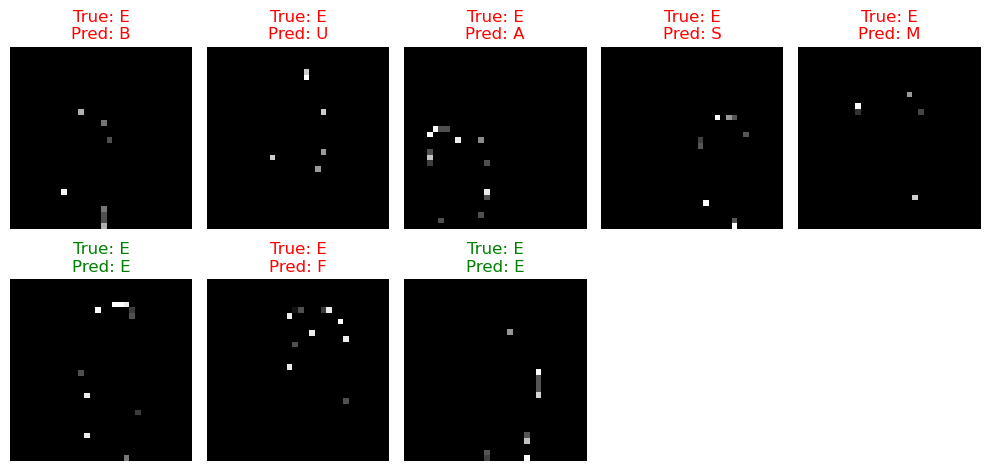

Class 'F' - Accuracy: 87.50%


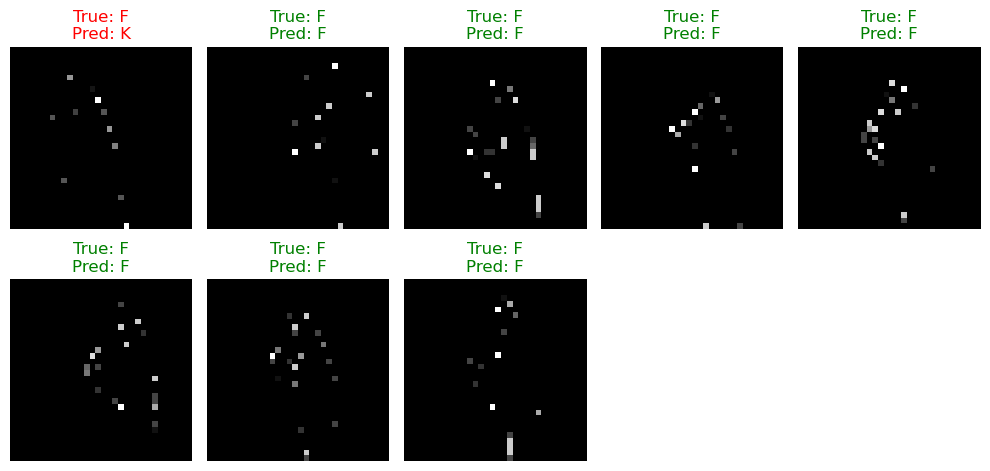

Class 'G' - Accuracy: 50.00%


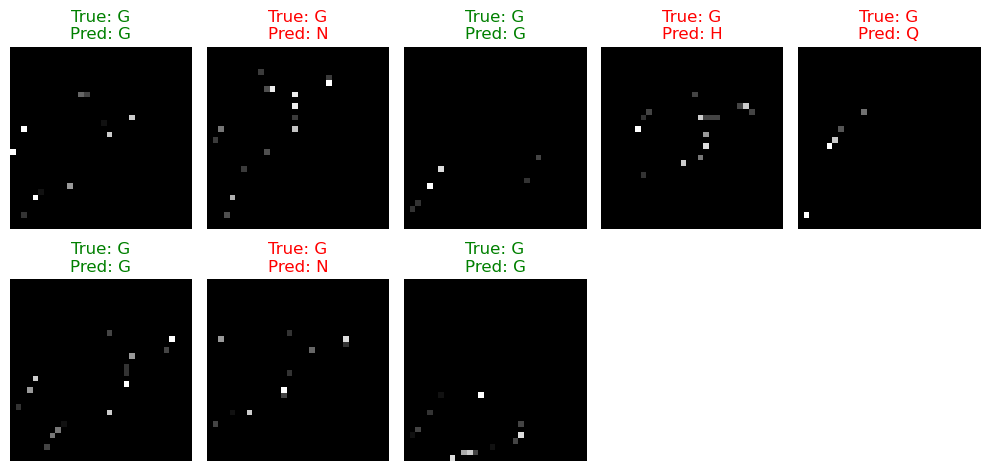

Class 'H' - Accuracy: 87.50%


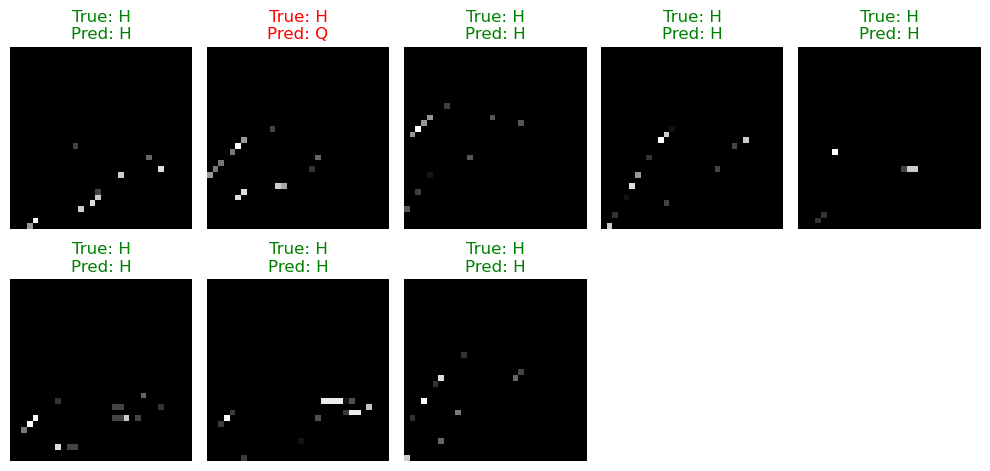

Class 'I' - Accuracy: 62.50%


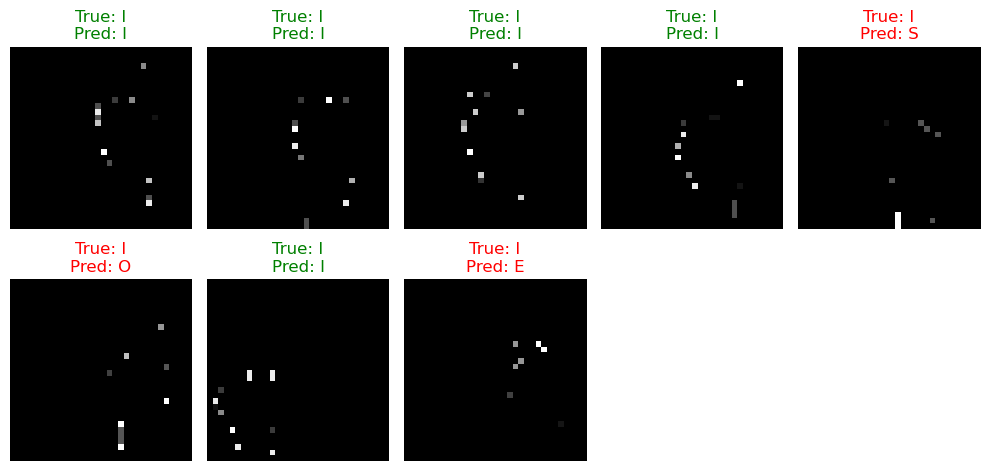

Class 'K' - Accuracy: 75.00%


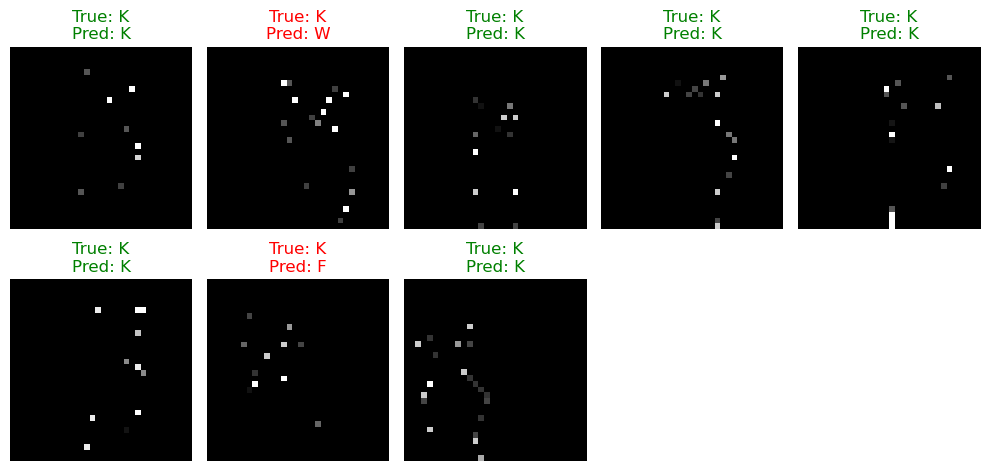

Class 'L' - Accuracy: 87.50%


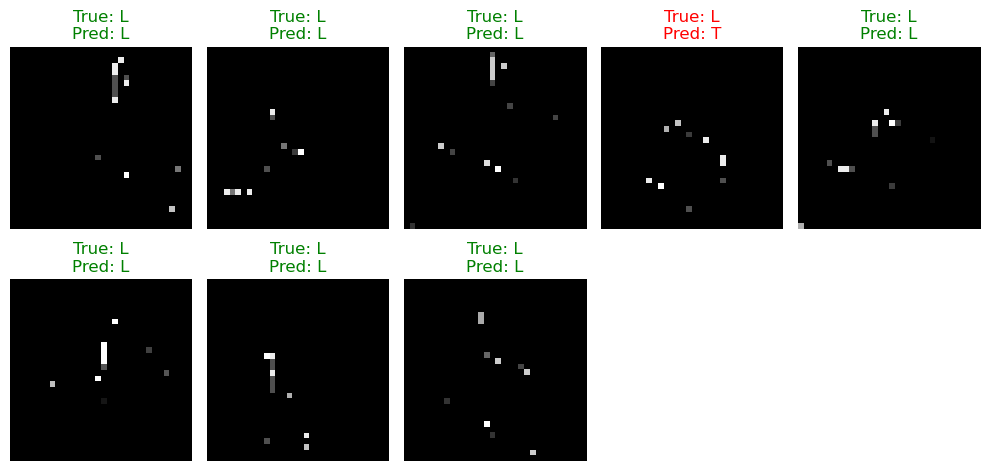

Class 'M' - Accuracy: 62.50%


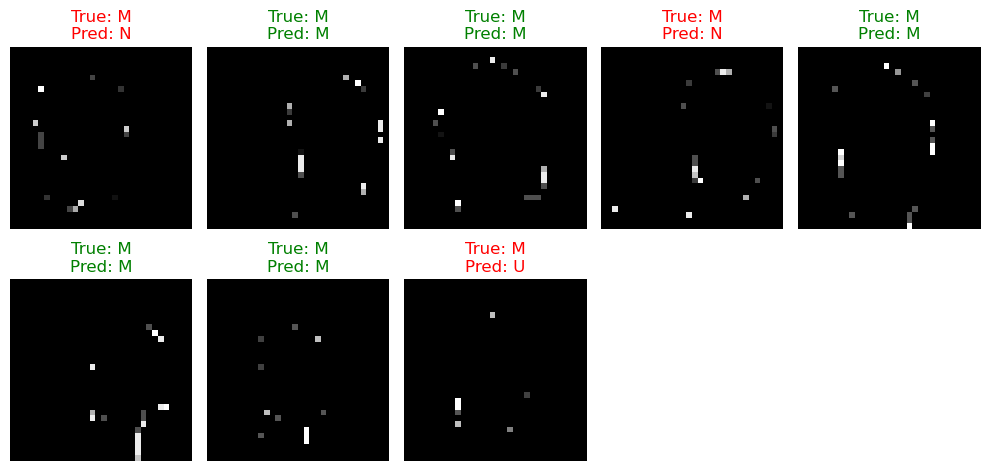

Class 'N' - Accuracy: 75.00%


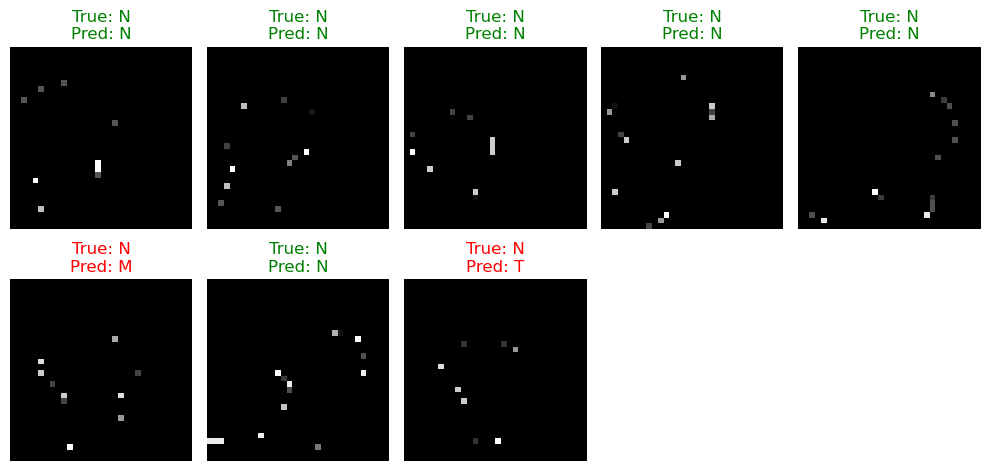

Class 'O' - Accuracy: 50.00%


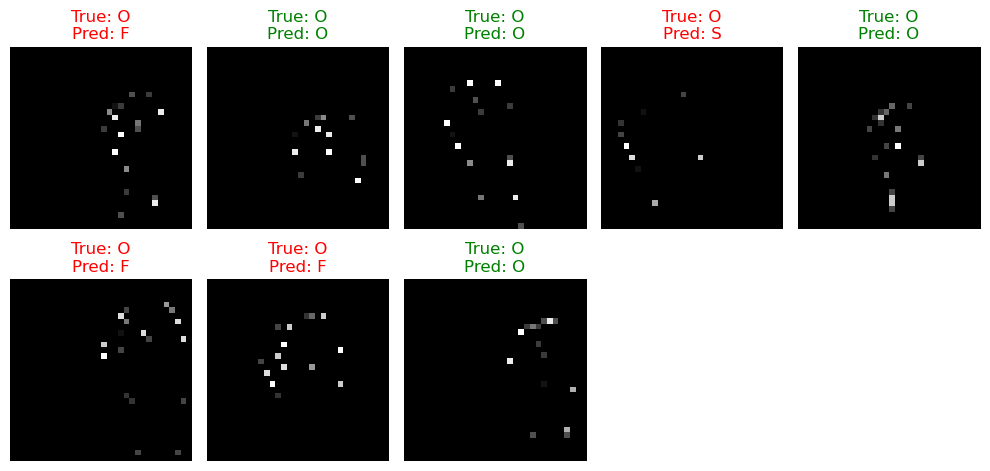

Class 'P' - Accuracy: 87.50%


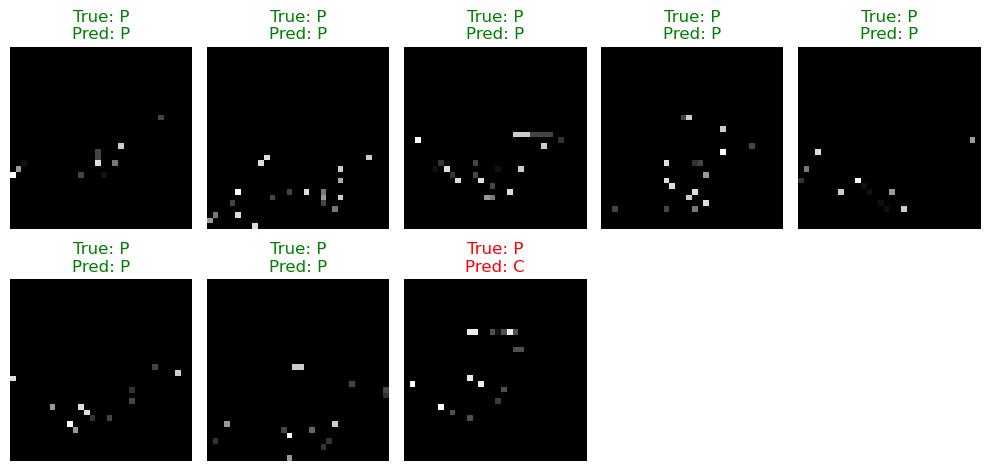

Class 'Q' - Accuracy: 75.00%


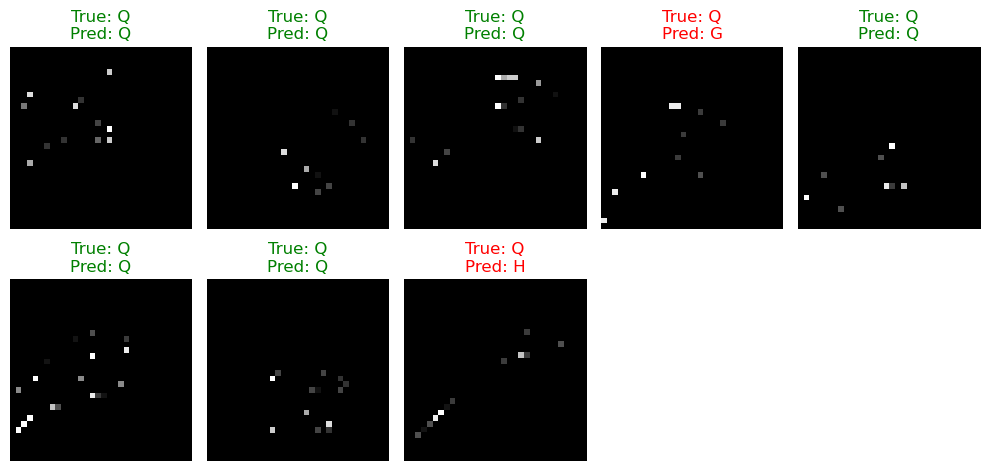

Class 'R' - Accuracy: 75.00%


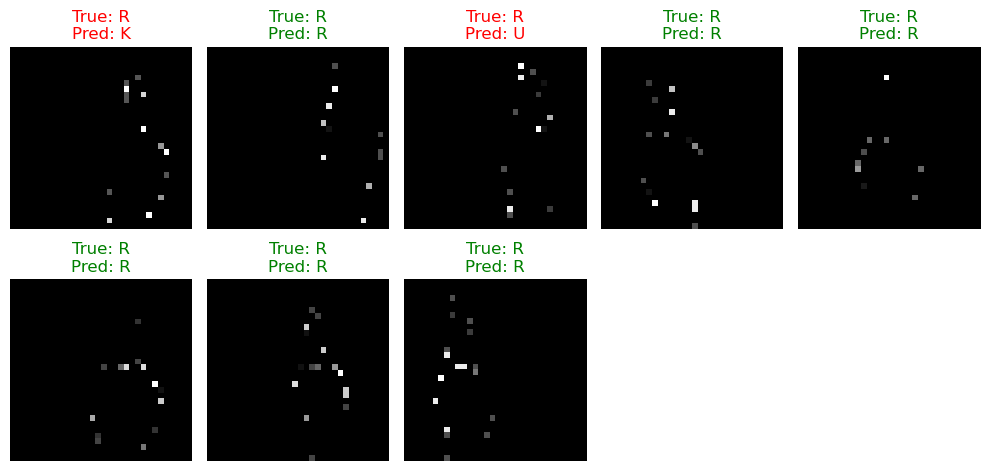

Class 'S' - Accuracy: 50.00%


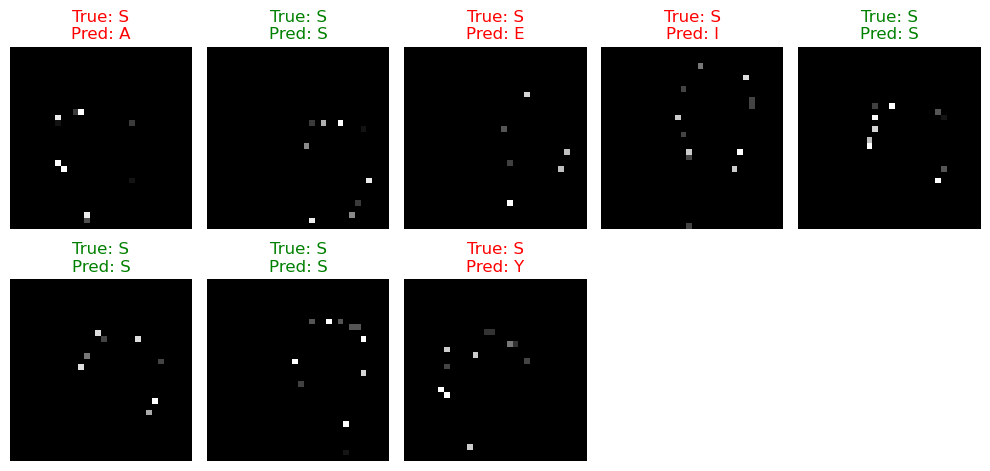

Class 'T' - Accuracy: 75.00%


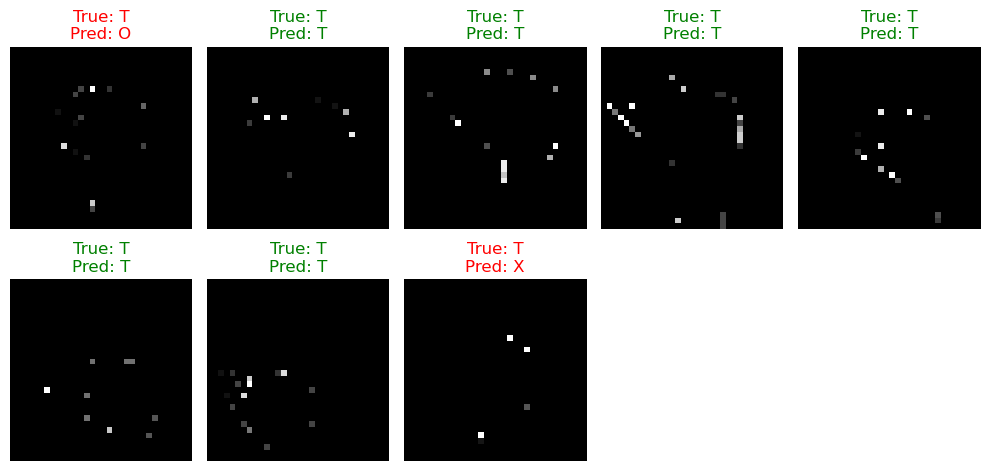

Class 'U' - Accuracy: 75.00%


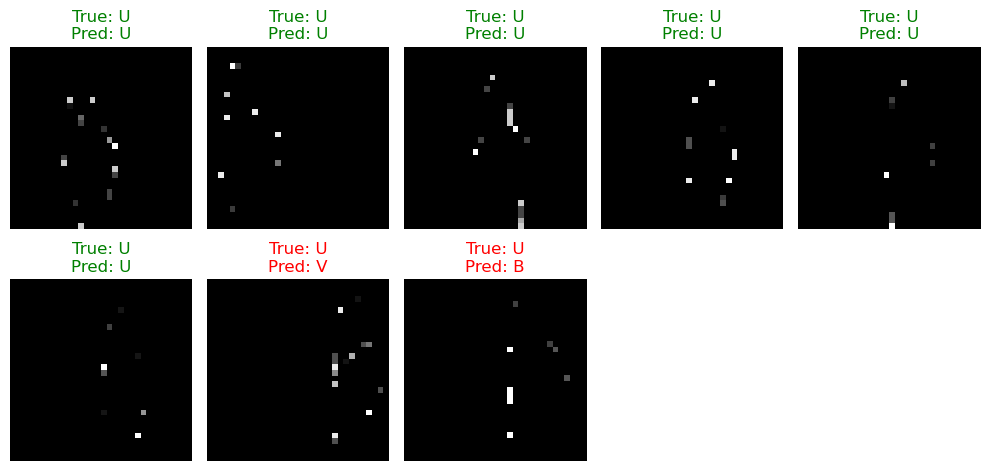

Class 'V' - Accuracy: 62.50%


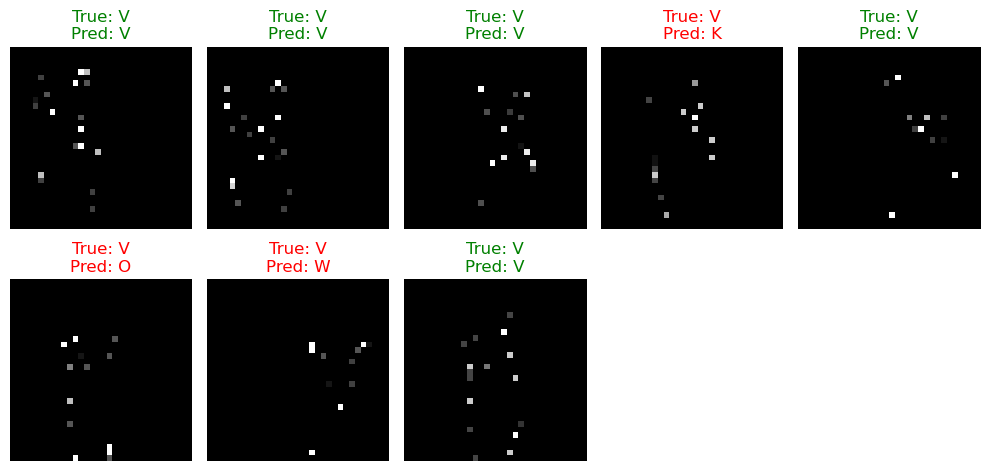

Class 'W' - Accuracy: 75.00%


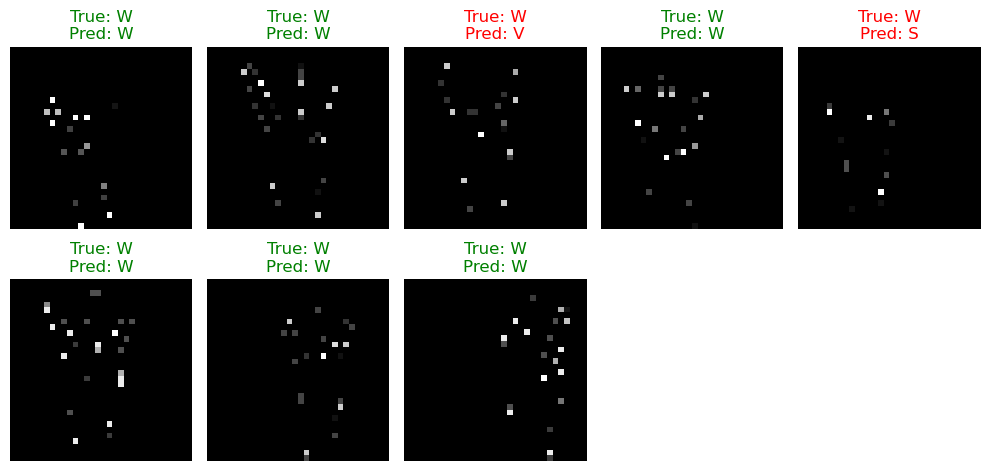

Class 'X' - Accuracy: 87.50%


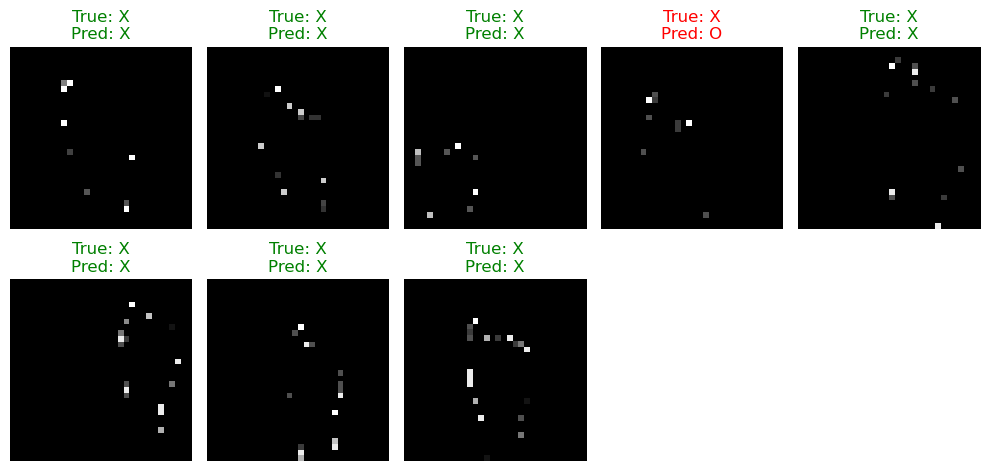

Class 'Y' - Accuracy: 62.50%


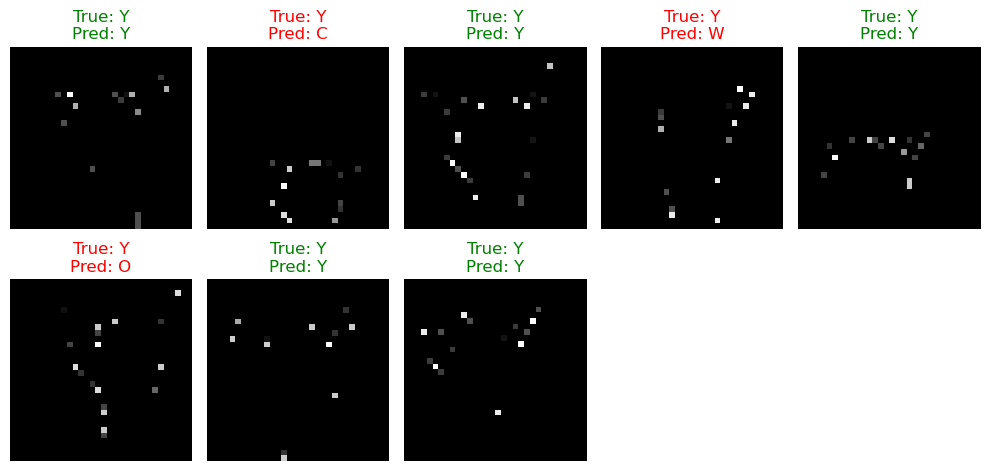

Overall accuracy across all valid classes: 69.27%


In [43]:
analyze_model_predictions2(model, 
                          X_test, 
                          y_test, 
                          label_map, 
                          img_size=(32, 32), 
                          num_predictions=15, 
                          num_per_class=8)

## Conclusion and Recomendation

It did not perform aswell as I had hoped with the argumentation tweaks I made to the model. Since i'm out of time UI would be able to further explaore and tweak this datset to is best. I still think with the right tweaks this model could be used for making perdictions evetually. 

My recomendation is that there still needs to be tweaked with argumenations in order to get the desired result. With the tweaking I mean maybe scale out the background more, maybe improving a bit of the edges around the hands by playing around with the treshholds, playing around with the amount of data that you want to use for you training. Also Trying out different ways to blur your images, maybe that can increase the dataset because this is something out found way to late to try for this analysis. 

A other recomendation is to add a confusion matrix to this result to get a better overview of wat is predicted wrong. So that you can easily see which letter is predicted incorrectly to better tweak your model. An example of this is when you see that the A is predicted wrong very often, and you can then see which letter is very similar, causing it to predict wrongly.

My overall conclusion is that when this dataset is tweaked more it can be used as a model to predict sing langauage.